# 02 — Data Understanding

**Proyek:** klasifikasi audio kelas berisik vs non-berisik  
**Sumber data:** rekaman mahasiswa Proyek Sains Data A, Universitas Trunojoyo Madura  
**Sifat notebook:** eksplorasi dan verifikasi kualitas data; **belum** melatih model

Notebook ini dibangun dari file `.py` berurutan di `notebooks/02_data_understanding/`. Setiap file menjadi satu code cell. Seluruh angka berasal dari eksekusi pada `raw_audio/` yang sebenarnya.

## Ringkasan aktual

| Item | Nilai |
|---|---:|
| Total file | **200** |
| NIM unik | **35** |
| File berisik | **100** |
| File non-berisik | **100** |
| NIM lengkap 6 file | **30 / 35** |
| Kombinasi take hilang | **10** |
| Hash unik | **177** |
| File terlibat duplikat eksak | **41** |
| Grup duplikat lintas NIM | **14** |
| Grup duplikat lintas label | **1** |
| File berdurasi tepat 30 detik | **200 / 200** |
| File gagal dibaca | **0** |

> **Kesimpulan awal:** data mentah cukup untuk dianalisis, tetapi **belum siap dimodelkan**. Ada duplikasi eksak lintas NIM, satu konflik label, dan lima NIM yang tidak lengkap. Semua temuan harus diselesaikan pada tahap 03.

## Alur analisis

1. Menyiapkan pustaka dan konfigurasi.
2. Menginventarisasi file dan mem-parse identitas.
3. Membaca metadata serta statistik sinyal.
4. Memvalidasi NIM, take, label, dan kelengkapan protokol.
5. Mendeteksi duplikat eksak.
6. Memeriksa integritas teknis.
7. Merangkum dataset dan membuat EDA.
8. Menyusun temuan kualitas dan laporan.
9. Memvalidasi seluruh artefak sebelum lanjut ke tahap 03.

## 1. Pustaka dan pengaturan dasar

**Apa yang dilakukan:** mengimpor `pandas`, `numpy`, `soundfile`, `librosa`, `matplotlib`, dan `seaborn`, lalu menetapkan tema grafik serta `random_state`.

**Mengapa:** analisis harus memakai versi pustaka yang tercatat dan hasil yang dapat direproduksi. `soundfile` dipakai untuk membaca metadata dan sampel MP3 tanpa mengubah file asli. FFmpeg dicatat karena nanti diperlukan pada konversi tahap 03.

**Cara membaca:** tabel menunjukkan versi runtime. Jika FFmpeg bertuliskan “tidak ditemukan”, konversi MP3 belum dapat dijalankan sampai FFmpeg tersedia di `PATH`.

In [1]:
# Tujuan: menyiapkan pustaka dan pengaturan dasar untuk analisis Data Understanding.
# Proses: mengimpor pustaka, menetapkan opsi tampilan, tema grafik, dan random seed.
# Output: ringkasan versi pustaka yang benar-benar digunakan.

import hashlib
import json
import math
import platform
import re
import shutil
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found.*")

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["axes.titleweight"] = "bold"

RANDOM_STATE = 42

library_versions = pd.DataFrame(
    {
        "komponen": [
            "Python",
            "numpy",
            "pandas",
            "librosa",
            "soundfile",
            "matplotlib",
            "seaborn",
            "FFmpeg (PATH)",
        ],
        "versi": [
            platform.python_version(),
            np.__version__,
            pd.__version__,
            librosa.__version__,
            sf.__version__,
            plt.matplotlib.__version__,
            sns.__version__,
            shutil.which("ffmpeg") or "tidak ditemukan",
        ],
    }
)

display(library_versions)

,komponen,versi
0,Python,3.11.9
1,numpy,2.4.6
2,pandas,2.3.3
3,librosa,0.11.0
4,soundfile,0.14.0
5,matplotlib,3.11.0
6,seaborn,0.13.2
7,FFmpeg (PATH),tidak ditemukan


## 2. Path proyek dan konfigurasi pemeriksaan

**Apa yang dilakukan:** menemukan root proyek, membuat folder artefak, dan menetapkan pola nama file, durasi acuan, toleransi, serta ambang level sinyal rendah.

**Mengapa:** semua tahap harus membaca dan menulis ke lokasi yang sama. Pola nama file dipakai untuk mengekstrak NIM, kelas, dan take secara konservatif—bukan menebak.

**Cara membaca:** `RAW_DIR` adalah sumber read-only. Seluruh keluaran notebook ini disimpan di `artifacts/02_data_understanding/`, sehingga data mentah tidak tersentuh.

In [2]:
# Tujuan: menemukan lokasi proyek dan menetapkan konfigurasi analisis.
# Proses: memeriksa folder proyek, membuat folder artefak, dan menetapkan pola identitas file.
# Output: path proyek, path data, folder artefak, dan konfigurasi pemeriksaan yang akan dipakai.


def locate_project_root(start):
    for candidate in [start, *start.parents]:
        if (candidate / "raw_audio").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("Folder proyek dengan raw_audio/ dan notebooks/ tidak ditemukan.")


PROJECT_ROOT = locate_project_root(Path.cwd().resolve())
RAW_DIR = PROJECT_ROOT / "raw_audio"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "02_data_understanding"
FIGURE_DIR = ARTIFACT_DIR / "figures"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

FILENAME_PATTERN = re.compile(
    r"^(?P<nim>\d{2}-\d{3})_(?P<label_text>berisik|non-berisik)_(?P<take>\d+)\.mp3$",
    flags=re.IGNORECASE,
)
FOLDER_LABEL_MAP = {"berisik": 1, "non-berisik": 0}
LABEL_NAME_MAP = {1: "berisik", 0: "non-berisik"}

EXPECTED_DURATION_S = 30.0
DURATION_TOLERANCE_S = 0.01
LOW_PEAK_THRESHOLD = 0.05
AUDIO_EXTENSIONS = {".mp3"}

config = pd.DataFrame(
    {
        "parameter": [
            "PROJECT_ROOT",
            "RAW_DIR",
            "ARTIFACT_DIR",
            "FIGURE_DIR",
            "durasi acuan",
            "toleransi durasi",
            "ambang peak level rendah",
            "pola nama file",
        ],
        "nilai": [
            str(PROJECT_ROOT),
            str(RAW_DIR),
            str(ARTIFACT_DIR),
            str(FIGURE_DIR),
            f"{EXPECTED_DURATION_S:.1f} detik",
            f"{DURATION_TOLERANCE_S:.2f} detik",
            f"peak < {LOW_PEAK_THRESHOLD:.2f}",
            FILENAME_PATTERN.pattern,
        ],
    }
)

display(config)
print("FFmpeg di PATH:", shutil.which("ffmpeg") or "tidak ditemukan")

,parameter,nilai
0,PROJECT_ROOT,C:\Users\ASUS\Downloads\dataset_30_detik
1,RAW_DIR,C:\Users\ASUS\Downloads\dataset_30_detik\raw_a...
2,ARTIFACT_DIR,C:\Users\ASUS\Downloads\dataset_30_detik\artif...
3,FIGURE_DIR,C:\Users\ASUS\Downloads\dataset_30_detik\artif...
4,durasi acuan,30.0 detik
5,toleransi durasi,0.01 detik
6,ambang peak level rendah,peak < 0.05
7,pola nama file,^(?P<nim>\d{2}-\d{3})_(?P<label_text>berisik|n...


FFmpeg di PATH: tidak ditemukan


## 3. Konteks pengumpulan dan inventaris file

Data dibuat oleh mahasiswa PSD-A, Universitas Trunojoyo Madura. Protokol awal: setiap mahasiswa merekam **6 audio** di laboratorium—3 take berisik dan 3 take non-berisik—dalam format MP3, lalu dikumpulkan melalui Google Drive bersama.

Laporan awal menyebutkan 200 file (100 per kelas). Hasil hitung aktual juga **200 file** dengan **100 berisik** dan **100 non-berisik**, tetapi jumlah NIM adalah **35**, bukan 33,33. Ini terjadi karena protokol 6 file per NIM tidak lengkap untuk sebagian NIM.

**Apa yang dilakukan:** membaca semua file di `raw_audio/`, mem-parse pola `NIM_kelas_take.mp3`, dan membandingkan label dari folder dengan label dari nama file.

**Mengapa:** identitas yang salah akan merusak split berbasis NIM. Label tidak boleh ditebak dari kemiripan audio.

**Cara membaca:** `label` hanya diisi jika label folder dan nama file sepakat. Jika tidak, nilainya kosong dan file harus ditinjau, bukan dipaksakan.

In [3]:
# Tujuan: menginventarisasi seluruh file mentah dan mem-parse identitas dari nama file.
# Proses: membaca struktur folder, mengekstrak NIM/kelas/take, dan membandingkan label folder dengan label nama file.
# Output: tabel inventaris per file dan ringkasan hasil parsing.

inventory_rows = []

for path in sorted(RAW_DIR.rglob("*")):
    if not path.is_file():
        continue

    relative_path = path.relative_to(RAW_DIR).as_posix()
    relative_parts = Path(relative_path).parts
    folder = relative_parts[0] if len(relative_parts) > 1 else "(root)"
    match = FILENAME_PATTERN.match(path.name)

    folder_label = FOLDER_LABEL_MAP.get(folder.lower(), np.nan)
    filename_label = np.nan
    nim = pd.NA
    take = pd.NA

    if match:
        nim = match.group("nim")
        take = int(match.group("take"))
        filename_label = 1 if match.group("label_text").lower() == "berisik" else 0

    label_match = (
        pd.notna(folder_label)
        and pd.notna(filename_label)
        and int(folder_label) == int(filename_label)
    )
    label = int(folder_label) if label_match else np.nan

    inventory_rows.append(
        {
            "relative_path": relative_path,
            "file": path.name,
            "folder": folder,
            "extension": path.suffix.lower(),
            "size_bytes": path.stat().st_size,
            "name_parse_ok": bool(match),
            "nim": nim,
            "take": take,
            "label_from_folder": folder_label,
            "label_from_filename": filename_label,
            "label_match": label_match,
            "label": label,
            "extension_ok": path.suffix.lower() in AUDIO_EXTENSIONS,
        }
    )

inventory = pd.DataFrame(inventory_rows)
inventory = inventory.sort_values("relative_path").reset_index(drop=True)

inventory_counts = pd.DataFrame(
    {
        "pemeriksaan": [
            "total file",
            "nama file sesuai pola",
            "nama file tidak sesuai pola",
            "ekstensi MP3",
            "label folder = label nama file",
            "label tidak dapat dipastikan",
        ],
        "jumlah": [
            len(inventory),
            int(inventory["name_parse_ok"].sum()),
            int((~inventory["name_parse_ok"]).sum()),
            int(inventory["extension_ok"].sum()),
            int(inventory["label_match"].sum()),
            int(inventory["label"].isna().sum()),
        ],
    }
)

display(inventory_counts)
display(inventory["folder"].value_counts().rename_axis("folder").reset_index(name="jumlah"))
display(inventory.head(8))

unparsed = inventory.loc[~inventory["name_parse_ok"], ["relative_path"]]
if len(unparsed):
    display(unparsed)
else:
    print("Tidak ada file yang gagal diparse.")

mismatched = inventory.loc[~inventory["label_match"], ["relative_path", "label_from_folder", "label_from_filename"]]
if len(mismatched):
    display(mismatched)
else:
    print("Tidak ada pertentangan label folder vs nama file.")

inventory.to_csv(ARTIFACT_DIR / "inventory_raw.csv", index=False)
print(f"Inventaris disimpan: {ARTIFACT_DIR / 'inventory_raw.csv'} ({len(inventory)} baris)")

,pemeriksaan,jumlah
0,total file,200
1,nama file sesuai pola,200
2,nama file tidak sesuai pola,0
3,ekstensi MP3,200
4,label folder = label nama file,200
5,label tidak dapat dipastikan,0


,folder,jumlah
0,berisik,100
1,non-berisik,100


,relative_path,file,folder,extension,size_bytes,name_parse_ok,nim,take,label_from_folder,label_from_filename,label_match,label,extension_ok
0,berisik/24-003_berisik_1.mp3,24-003_berisik_1.mp3,berisik,.mp3,593502,True,24-003,1,1,1,True,1,True
1,berisik/24-003_berisik_2.mp3,24-003_berisik_2.mp3,berisik,.mp3,494205,True,24-003,2,1,1,True,1,True
2,berisik/24-003_berisik_3.mp3,24-003_berisik_3.mp3,berisik,.mp3,487629,True,24-003,3,1,1,True,1,True
3,berisik/24-006_berisik_1.mp3,24-006_berisik_1.mp3,berisik,.mp3,478366,True,24-006,1,1,1,True,1,True
4,berisik/24-006_berisik_2.mp3,24-006_berisik_2.mp3,berisik,.mp3,492134,True,24-006,2,1,1,True,1,True
5,berisik/24-006_berisik_3.mp3,24-006_berisik_3.mp3,berisik,.mp3,474068,True,24-006,3,1,1,True,1,True
6,berisik/24-007_berisik_1.mp3,24-007_berisik_1.mp3,berisik,.mp3,238173,True,24-007,1,1,1,True,1,True
7,berisik/24-007_berisik_2.mp3,24-007_berisik_2.mp3,berisik,.mp3,235413,True,24-007,2,1,1,True,1,True


Tidak ada file yang gagal diparse.
Tidak ada pertentangan label folder vs nama file.
Inventaris disimpan: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\02_data_understanding\inventory_raw.csv (200 baris)


## 4. Metadata dan statistik sinyal dasar

Durasi hasil decode dihitung dari jumlah frame dan sample rate:

$$T = \frac{N_{\text{frames}}}{f_s}$$

dengan $N_{\text{frames}}$ = jumlah frame audio dan $f_s$ = sample rate (Hz). Estimasi bitrate dari ukuran file adalah:

$$\text{bitrate}_{\text{kbps}} \approx \frac{8 \times \text{ukuran byte}}{1000 \times T}$$

**Ilustrasi angka kecil (bukan data audio asli):** 480.000 frame pada 16.000 Hz menghasilkan $480000/16000 = 30$ detik. File 600.000 byte selama 30 detik menghasilkan $8 \times 600000 / (1000 \times 30) = 160$ kbps. Perhitungan aktual dijalankan pada seluruh 200 file oleh cell berikut.

**Apa yang dilakukan:** membaca seluruh sampel dengan `soundfile`, menghitung durasi, sample rate, channel, peak, RMS, proporsi nol, NaN, Inf, dan estimasi bitrate.

**Mengapa:** metadata menentukan kebutuhan resampling, downmix, dan pemeriksaan sinyal kosong. Peak > 1,0 dapat muncul sebagai overshoot decoder MP3 dan bukan otomatis berarti file rusak.

**Cara membaca:** fokus pada sebaran sample rate/channel, nilai minimum peak/RMS, serta jumlah file yang gagal dibaca. Nilai detail per file tersimpan di `audio_metadata.csv`.

In [4]:
# Tujuan: membaca metadata dan statistik sinyal dasar dari setiap file audio mentah.
# Proses: membuka file dengan soundfile, membaca seluruh sampel, menghitung durasi, sample rate, channel, peak, RMS, dan pemeriksaan NaN/Inf.
# Output: tabel metadata per file dan ringkasan kualitas pembacaan.

metadata_rows = []

for row in inventory.itertuples(index=False):
    path = RAW_DIR / row.relative_path
    record = {
        "relative_path": row.relative_path,
        "read_ok": False,
        "read_error": "",
    }

    try:
        info = sf.info(str(path))
        data, samplerate = sf.read(str(path), dtype="float32", always_2d=True)
        data_float = data.astype(np.float64)

        peak_abs = float(np.max(np.abs(data_float))) if data_float.size else 0.0
        rms = float(np.sqrt(np.mean(np.square(data_float)))) if data_float.size else 0.0
        zero_fraction = float(np.mean(data_float == 0.0)) if data_float.size else 1.0

        record.update(
            {
                "read_ok": True,
                "format": info.format,
                "subtype": info.subtype,
                "samplerate": int(info.samplerate),
                "channels": int(info.channels),
                "frames": int(info.frames),
                "duration_info_s": float(info.duration),
                "decoded_frames": int(data.shape[0]),
                "duration_decoded_s": float(data.shape[0] / samplerate),
                "peak_abs": peak_abs,
                "rms": rms,
                "zero_fraction": zero_fraction,
                "nan_count": int(np.isnan(data_float).sum()),
                "inf_count": int(np.isinf(data_float).sum()),
                "bitrate_kbps_estimate": float(row.size_bytes * 8 / info.duration / 1000) if info.duration > 0 else np.nan,
                "peak_over_one": bool(peak_abs > 1.0),
            }
        )
    except Exception as exc:
        record["read_error"] = f"{type(exc).__name__}: {exc}"

    metadata_rows.append(record)

audio_metadata = pd.DataFrame(metadata_rows)

read_summary = pd.DataFrame(
    {
        "pemeriksaan": [
            "file berhasil dibaca",
            "file gagal dibaca",
            "file dengan NaN",
            "file dengan Inf",
            "file dengan peak > 1.0",
        ],
        "jumlah": [
            int(audio_metadata["read_ok"].sum()),
            int((~audio_metadata["read_ok"]).sum()),
            int((audio_metadata["nan_count"] > 0).sum()),
            int((audio_metadata["inf_count"] > 0).sum()),
            int(audio_metadata["peak_over_one"].fillna(False).sum()),
        ],
    }
)

display(read_summary)
display(
    audio_metadata[
        ["duration_decoded_s", "samplerate", "channels", "peak_abs", "rms", "bitrate_kbps_estimate"]
    ].describe().T
)
display(audio_metadata["samplerate"].value_counts().rename_axis("samplerate").reset_index(name="jumlah"))
display(audio_metadata["channels"].value_counts().rename_axis("channels").reset_index(name="jumlah"))

failed = audio_metadata.loc[~audio_metadata["read_ok"], ["relative_path", "read_error"]]
if len(failed):
    display(failed)
else:
    print("Tidak ada file yang gagal dibaca.")

audio_metadata.to_csv(ARTIFACT_DIR / "audio_metadata.csv", index=False)
print(f"Metadata disimpan: {ARTIFACT_DIR / 'audio_metadata.csv'} ({len(audio_metadata)} baris)")

,pemeriksaan,jumlah
0,file berhasil dibaca,200
1,file gagal dibaca,0
2,file dengan NaN,0
3,file dengan Inf,0
4,file dengan peak > 1.0,36


,count,mean,std,min,25%,50%,75%,max
duration_decoded_s,200.0,30.000000,0.000000,30.000000,30.000000,30.000000,30.000000,30.000000
samplerate,200.0,45694.500000,5550.328864,16000.000000,44100.000000,48000.000000,48000.000000,48000.000000
channels,200.0,1.720000,0.450126,1.000000,1.000000,2.000000,2.000000,2.000000
peak_abs,200.0,0.641976,0.347747,0.021961,0.364895,0.674268,0.920386,1.511773
rms,200.0,0.073838,0.069267,0.001195,0.023447,0.050225,0.113514,0.314380
bitrate_kbps_estimate,200.0,125.722084,41.044135,33.468000,90.892000,127.752533,157.881600,203.193867


,samplerate,jumlah
0,48000,125
1,44100,69
2,16000,6


,channels,jumlah
0,2,144
1,1,56


Tidak ada file yang gagal dibaca.
Metadata disimpan: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\02_data_understanding\audio_metadata.csv (200 baris)


## 5. Validasi NIM, take, label, dan kelengkapan

Protokol awal mengharapkan 6 file per NIM. Persentase kelengkapan dihitung sebagai:

$$\text{kelengkapan} = \frac{\text{jumlah file aktual}}{6 \times \text{jumlah NIM}} \times 100\%$$

**Apa yang dilakukan:** memeriksa path unik, NIM unik, distribusi take, benturan identitas, NIM dengan satu kelas, NIM yang tidak lengkap, dan kombinasi NIM-kelas-take yang hilang.

**Mengapa:** split berbasis NIM hanya sah jika NIM terbaca benar. Take yang hilang tidak boleh diisi dengan tebakan.

**Cara membaca:** tabel `missing_takes.csv` adalah daftar eksplisit apa yang tidak ada. Dari data aktual, **30 dari 35 NIM** lengkap; **10 kombinasi** hilang. NIM 24-123 hanya memiliki kelas berisik.

In [5]:
# Tujuan: memvalidasi identitas NIM, take, label, dan kelengkapan protokol 6 file per NIM.
# Proses: menghitung NIM unik, distribusi kelas/take, kombinasi yang hilang, dan benturan identitas.
# Output: tabel pemeriksaan identitas, daftar take yang hilang, dan ringkasan per NIM.

valid_identity = inventory.loc[inventory["name_parse_ok"] & inventory["label"].notna()].copy()
valid_identity["label"] = valid_identity["label"].astype(int)
valid_identity["take"] = valid_identity["take"].astype(int)

nim_values = sorted(valid_identity["nim"].dropna().unique())
expected_index = pd.MultiIndex.from_product(
    [nim_values, [0, 1], [1, 2, 3]],
    names=["nim", "label", "take"],
)
actual_index = pd.MultiIndex.from_frame(valid_identity[["nim", "label", "take"]])
missing_index = expected_index.difference(actual_index)

missing_takes = missing_index.to_frame(index=False)
missing_takes["label_name"] = missing_takes["label"].map(LABEL_NAME_MAP)
missing_takes = missing_takes.sort_values(["nim", "label", "take"]).reset_index(drop=True)

files_per_nim = valid_identity.groupby("nim").size().rename("jumlah_file")
incomplete_nims = files_per_nim.loc[files_per_nim != 6]
missing_per_nim = missing_takes.groupby("nim").size().rename("take_hilang")

nim_class_matrix = (
    valid_identity.pivot_table(index="nim", columns="label", values="relative_path", aggfunc="count", fill_value=0)
    .rename(columns=LABEL_NAME_MAP)
)
nim_class_matrix["total"] = nim_class_matrix.sum(axis=1)
nim_class_matrix["take_hilang"] = missing_per_nim.reindex(nim_class_matrix.index).fillna(0).astype(int)
nim_class_matrix["lengkap_6_file"] = nim_class_matrix["total"].eq(6)

identity_checks = pd.DataFrame(
    {
        "pemeriksaan": [
            "total file",
            "path unik",
            "nama file unik",
            "NIM unik",
            "nama file gagal diparse",
            "label folder vs nama tidak cocok",
            "identitas NIM-label-take duplikat",
            "NIM hanya memiliki satu kelas",
            "NIM dengan jumlah file != 6",
            "kombinasi NIM-kelas-take hilang",
            "file jika semua NIM lengkap 6 file",
            "persentase kelengkapan terhadap 6 file/NIM",
        ],
        "nilai": [
            len(inventory),
            inventory["relative_path"].nunique(),
            inventory["file"].nunique(),
            len(nim_values),
            int((~inventory["name_parse_ok"]).sum()),
            int((~inventory["label_match"]).sum()),
            int(valid_identity.duplicated(["nim", "label", "take"], keep=False).sum()),
            int((nim_class_matrix[["berisik", "non-berisik"]] == 0).any(axis=1).sum()),
            int((files_per_nim != 6).sum()),
            int(len(missing_takes)),
            int(len(nim_values) * 6),
            f"{len(valid_identity) / (len(nim_values) * 6) * 100:.2f}%",
        ],
    }
)

display(identity_checks)
display(valid_identity.groupby(["label", "take"]).size().unstack(fill_value=0).rename(index=LABEL_NAME_MAP))
display(files_per_nim.value_counts().sort_index().rename_axis("file_per_NIM").reset_index(name="jumlah_NIM"))
display(nim_class_matrix)

if len(missing_takes):
    print(f"Take yang hilang: {len(missing_takes)} kombinasi pada {missing_takes['nim'].nunique()} NIM")
    display(missing_takes)
else:
    print("Semua kombinasi NIM-kelas-take lengkap.")

missing_takes.to_csv(ARTIFACT_DIR / "missing_takes.csv", index=False)
nim_class_matrix.reset_index().to_csv(ARTIFACT_DIR / "nim_class_matrix.csv", index=False)
print(f"Daftar take hilang disimpan: {ARTIFACT_DIR / 'missing_takes.csv'}")

,pemeriksaan,nilai
0,total file,200
1,path unik,200
2,nama file unik,200
3,NIM unik,35
4,nama file gagal diparse,0
5,label folder vs nama tidak cocok,0
6,identitas NIM-label-take duplikat,0
7,NIM hanya memiliki satu kelas,1
8,NIM dengan jumlah file != 6,5
9,kombinasi NIM-kelas-take hilang,10


take,1,2,3
label,,,
non-berisik,32,34,34
berisik,33,32,35


,file_per_NIM,jumlah_NIM
0,2,1
1,4,2
2,5,2
3,6,30


label,non-berisik,berisik,total,take_hilang,lengkap_6_file
nim,,,,,
24-003,2,3,5,1,False
24-006,3,3,6,0,True
24-007,3,3,6,0,True
24-026,3,3,6,0,True
24-027,3,3,6,0,True
24-031,3,3,6,0,True
24-034,3,3,6,0,True
24-053,3,2,5,1,False
24-068,3,3,6,0,True


Take yang hilang: 10 kombinasi pada 5 NIM


,nim,label,take,label_name
0,24-003,0,1,non-berisik
1,24-053,1,2,berisik
2,24-123,0,1,non-berisik
3,24-123,0,2,non-berisik
4,24-123,0,3,non-berisik
5,24-123,1,2,berisik
6,24-169,1,1,berisik
7,24-169,1,2,berisik
8,24-228,0,1,non-berisik
9,24-228,1,1,berisik


Daftar take hilang disimpan: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\02_data_understanding\missing_takes.csv


## 6. Deteksi duplikat eksak

**Apa yang dilakukan:** menghitung SHA-256 setiap file, mengelompokkan hash identik, lalu menandai apakah grup duplikat berada dalam satu NIM, lintas NIM, atau lintas label.

**Mengapa:** duplikat eksak tidak menambah informasi baru. Yang lebih penting, duplikat **lintas NIM** dapat membocorkan konten yang sama ke train dan test meskipun split dilakukan per NIM. Duplikat **lintas label** membuktikan adanya konflik label.

**Cara membaca:** hash identik berarti byte file identik, bukan sekadar mirip. Deteksi ini tidak memberi label baru dan tidak menghapus file.

Hasil aktual: **18 grup**, **41 file**, **177 hash unik**. Rinciannya: **14 grup lintas NIM**, **1 grup lintas label**, dan **3 grup dalam NIM yang sama**.

In [6]:
# Tujuan: mendeteksi duplikat eksak berdasarkan hash SHA-256 tanpa menghapus file apa pun.
# Proses: menghitung hash setiap file, mengelompokkan hash identik, dan menandai duplikat lintas NIM/lintas label.
# Output: tabel duplikat per file, ringkasan grup duplikat, dan statistik duplikasi.

hashed_inventory = inventory.copy()
hashed_inventory["sha256"] = [
    hashlib.sha256((RAW_DIR / rel).read_bytes()).hexdigest()
    for rel in hashed_inventory["relative_path"]
]

hash_groups = hashed_inventory.groupby("sha256", sort=False)
duplicate_group_rows = []
group_ids = {}
group_counter = 0

for sha256, group in sorted(hash_groups, key=lambda item: item[1]["relative_path"].min()):
    if len(group) <= 1:
        continue
    group_counter += 1
    group_id = f"DUP{group_counter:02d}"
    group_ids[sha256] = group_id
    labels = sorted(group["label"].dropna().astype(int).unique().tolist())
    nims = sorted(group["nim"].dropna().unique().tolist())
    takes = sorted(group["take"].dropna().astype(int).unique().tolist())
    if len(labels) > 1:
        scope = "cross_label"
    elif len(nims) > 1:
        scope = "cross_nim"
    else:
        scope = "within_nim"
    duplicate_group_rows.append(
        {
            "duplicate_group_id": group_id,
            "sha256": sha256,
            "n_files": len(group),
            "labels": ", ".join(LABEL_NAME_MAP[label] for label in labels),
            "n_labels": len(labels),
            "nims": ", ".join(nims),
            "n_nims": len(nims),
            "takes": ", ".join(str(take) for take in takes),
            "scope": scope,
            "files": " | ".join(sorted(group["relative_path"].tolist())),
        }
    )

duplicate_groups = pd.DataFrame(duplicate_group_rows)

hashed_inventory["duplicate_group_id"] = hashed_inventory["sha256"].map(group_ids).fillna("")
hashed_inventory["duplicate_group_size"] = hashed_inventory["sha256"].map(
    hashed_inventory["sha256"].value_counts()
).astype(int)
hashed_inventory["is_exact_duplicate"] = hashed_inventory["duplicate_group_size"].gt(1)

scope_map = (
    duplicate_groups.set_index("duplicate_group_id")["scope"].to_dict()
    if len(duplicate_groups)
    else {}
)
hashed_inventory["duplicate_scope"] = hashed_inventory["duplicate_group_id"].map(scope_map).fillna("unique")

duplicate_files = hashed_inventory.loc[
    hashed_inventory["is_exact_duplicate"],
    ["duplicate_group_id", "relative_path", "file", "nim", "label", "take", "duplicate_scope", "sha256"],
].sort_values(["duplicate_group_id", "relative_path"])

duplicate_counts = pd.DataFrame(
    {
        "pemeriksaan": [
            "total file",
            "hash unik",
            "file terlibat duplikat eksak",
            "grup duplikat eksak",
            "grup duplikat lintas NIM",
            "grup duplikat lintas label",
            "grup duplikat dalam NIM yang sama",
        ],
        "jumlah": [
            len(hashed_inventory),
            hashed_inventory["sha256"].nunique(),
            int(hashed_inventory["is_exact_duplicate"].sum()),
            len(duplicate_groups),
            int((duplicate_groups["scope"] == "cross_nim").sum()) if len(duplicate_groups) else 0,
            int((duplicate_groups["scope"] == "cross_label").sum()) if len(duplicate_groups) else 0,
            int((duplicate_groups["scope"] == "within_nim").sum()) if len(duplicate_groups) else 0,
        ],
    }
)

display(duplicate_counts)
if len(duplicate_groups):
    display(duplicate_groups.drop(columns=["sha256", "files"]))
    display(duplicate_files.drop(columns=["sha256"]))
else:
    print("Tidak ada duplikat eksak.")

hashed_inventory.to_csv(ARTIFACT_DIR / "inventory_with_hash.csv", index=False)
duplicate_groups.to_csv(ARTIFACT_DIR / "duplicate_groups.csv", index=False)
duplicate_files.to_csv(ARTIFACT_DIR / "duplicate_files.csv", index=False)
print(f"Tabel duplikat disimpan: {ARTIFACT_DIR / 'duplicate_groups.csv'}")

,pemeriksaan,jumlah
0,total file,200
1,hash unik,177
2,file terlibat duplikat eksak,41
3,grup duplikat eksak,18
4,grup duplikat lintas NIM,14
5,grup duplikat lintas label,1
6,grup duplikat dalam NIM yang sama,3


,duplicate_group_id,n_files,labels,n_labels,nims,n_nims,takes,scope
0,DUP01,2,berisik,1,"24-003, 24-053",2,"1, 3",cross_nim
1,DUP02,2,berisik,1,"24-003, 24-079",2,2,cross_nim
2,DUP03,3,berisik,1,"24-003, 24-079, 24-123",3,"1, 3",cross_nim
3,DUP04,2,"non-berisik, berisik",2,24-034,1,1,cross_label
4,DUP05,2,berisik,1,"24-071, 24-098",2,1,cross_nim
5,DUP06,2,berisik,1,"24-071, 24-098",2,2,cross_nim
6,DUP07,2,berisik,1,"24-071, 24-098",2,3,cross_nim
7,DUP08,2,berisik,1,"24-115, 24-190",2,3,cross_nim
8,DUP09,2,berisik,1,"24-123, 24-201",2,"1, 2",cross_nim
9,DUP10,3,berisik,1,24-157,1,"1, 2, 3",within_nim


,duplicate_group_id,relative_path,file,nim,label,take,duplicate_scope
0,DUP01,berisik/24-003_berisik_1.mp3,24-003_berisik_1.mp3,24-003,1,1,cross_nim
22,DUP01,berisik/24-053_berisik_3.mp3,24-053_berisik_3.mp3,24-053,1,3,cross_nim
1,DUP02,berisik/24-003_berisik_2.mp3,24-003_berisik_2.mp3,24-003,1,2,cross_nim
33,DUP02,berisik/24-079_berisik_2.mp3,24-079_berisik_2.mp3,24-079,1,2,cross_nim
2,DUP03,berisik/24-003_berisik_3.mp3,24-003_berisik_3.mp3,24-003,1,3,cross_nim
32,DUP03,berisik/24-079_berisik_1.mp3,24-079_berisik_1.mp3,24-079,1,1,cross_nim
60,DUP03,berisik/24-123_berisik_3.mp3,24-123_berisik_3.mp3,24-123,1,3,cross_nim
18,DUP04,berisik/24-034_berisik_1.mp3,24-034_berisik_1.mp3,24-034,1,1,cross_label
117,DUP04,non-berisik/24-034_non-berisik_1.mp3,24-034_non-berisik_1.mp3,24-034,0,1,cross_label
26,DUP05,berisik/24-071_berisik_1.mp3,24-071_berisik_1.mp3,24-071,1,1,cross_nim


Tabel duplikat disimpan: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\02_data_understanding\duplicate_groups.csv


## 7. Integritas teknis dan manifest mentah

Ambang yang dipakai: durasi acuan 30 detik dengan toleransi 0,01 detik; level sangat rendah jika peak absolut < 0,05. File dianggap gagal kritis jika tidak terbaca, tidak memiliki frame, bukan MP3, semua sampel nol, atau mengandung NaN/Inf.

**Apa yang dilakukan:** menggabungkan identitas, hash, dan metadata menjadi `manifest_raw.csv`, lalu memeriksa integritas.

**Mengapa:** manifest adalah jembatan antara file sumber dan tahap 03. Setiap baris harus dapat ditelusuri kembali ke satu file mentah.

**Cara membaca:** kegagalan kritis harus nol. File level rendah **tidak** otomatis dibuang; peak normalization akan memperkuat sinyal dan noise floor, sehingga keputusan harus berbasis audit.

Hasil aktual: **0 file gagal dibaca**, **0 sinyal kosong**, **0 file ber-NaN**, **0 file ber-Inf**, dan **3 file level rendah**. Ada **36 file** dengan peak > 1,0 akibat overshoot MP3.

In [7]:
# Tujuan: memeriksa integritas teknis file dan menyusun manifest mentah terpadu.
# Proses: menggabungkan identitas, hash, dan metadata; memeriksa file rusak, sinyal kosong, NaN/Inf, durasi, dan level sinyal sangat rendah.
# Output: manifest mentah, tabel pemeriksaan integritas, dan daftar file level rendah.

manifest_raw = hashed_inventory.merge(
    audio_metadata,
    on="relative_path",
    how="left",
    validate="one_to_one",
)

manifest_raw["duration_delta_s"] = manifest_raw["duration_decoded_s"] - EXPECTED_DURATION_S
manifest_raw["duration_status"] = np.select(
    [
        manifest_raw["duration_delta_s"].abs() <= DURATION_TOLERANCE_S,
        manifest_raw["duration_delta_s"] < 0,
        manifest_raw["duration_delta_s"] > 0,
    ],
    ["tepat_30_detik", "lebih_pendek", "lebih_panjang"],
    default="tidak_diketahui",
)
manifest_raw["all_zero"] = manifest_raw["peak_abs"].fillna(0).eq(0)
manifest_raw["low_level"] = manifest_raw["peak_abs"].fillna(0).lt(LOW_PEAK_THRESHOLD)
manifest_raw["numeric_invalid"] = manifest_raw["nan_count"].fillna(0).gt(0) | manifest_raw["inf_count"].fillna(0).gt(0)
manifest_raw["critical_failure"] = (
    ~manifest_raw["read_ok"].fillna(False)
    | manifest_raw["decoded_frames"].fillna(0).le(0)
    | ~manifest_raw["extension_ok"].fillna(False)
    | manifest_raw["all_zero"].fillna(False)
    | manifest_raw["numeric_invalid"].fillna(False)
)

integrity_checks = pd.DataFrame(
    {
        "pemeriksaan": [
            "file berhasil dibaca",
            "file gagal dibaca",
            "frame hasil decode > 0",
            "file dengan NaN",
            "file dengan Inf",
            "file dengan sinyal semua nol",
            "durasi tepat 30 detik",
            "durasi di luar toleransi",
            "peak > 1.0 (overshoot MP3)",
            "peak < 0.05 (level sangat rendah)",
            "kegagalan kritis",
        ],
        "jumlah": [
            int(manifest_raw["read_ok"].fillna(False).sum()),
            int((~manifest_raw["read_ok"].fillna(False)).sum()),
            int(manifest_raw["decoded_frames"].fillna(0).gt(0).sum()),
            int(manifest_raw["nan_count"].fillna(0).gt(0).sum()),
            int(manifest_raw["inf_count"].fillna(0).gt(0).sum()),
            int(manifest_raw["all_zero"].sum()),
            int(manifest_raw["duration_status"].eq("tepat_30_detik").sum()),
            int(manifest_raw["duration_status"].ne("tepat_30_detik").sum()),
            int(manifest_raw["peak_over_one"].fillna(False).sum()),
            int(manifest_raw["low_level"].sum()),
            int(manifest_raw["critical_failure"].sum()),
        ],
    }
)

low_level_files = manifest_raw.loc[
    manifest_raw["low_level"],
    ["relative_path", "nim", "label", "take", "peak_abs", "rms", "duration_decoded_s"],
].sort_values("peak_abs")

display(integrity_checks)
display(manifest_raw["duration_decoded_s"].describe().to_frame().T)
display(
    pd.crosstab(manifest_raw["samplerate"], manifest_raw["channels"])
    .rename_axis(index="samplerate", columns="channels")
)

if len(low_level_files):
    display(low_level_files)
else:
    print("Tidak ada file dengan level sangat rendah.")

manifest_raw.to_csv(ARTIFACT_DIR / "manifest_raw.csv", index=False)
integrity_checks.to_csv(ARTIFACT_DIR / "integrity_checks.csv", index=False)
low_level_files.to_csv(ARTIFACT_DIR / "low_level_files.csv", index=False)
print(f"Manifest mentah disimpan: {ARTIFACT_DIR / 'manifest_raw.csv'} ({len(manifest_raw)} baris)")

,pemeriksaan,jumlah
0,file berhasil dibaca,200
1,file gagal dibaca,0
2,frame hasil decode > 0,200
3,file dengan NaN,0
4,file dengan Inf,0
5,file dengan sinyal semua nol,0
6,durasi tepat 30 detik,200
7,durasi di luar toleransi,0
8,peak > 1.0 (overshoot MP3),36
9,peak < 0.05 (level sangat rendah),3


,count,mean,std,min,25%,50%,75%,max
duration_decoded_s,200.0,30.0,0.0,30.0,30.0,30.0,30.0,30.0


channels,1,2
samplerate,,
16000,6,0
44100,0,69
48000,50,75


,relative_path,nim,label,take,peak_abs,rms,duration_decoded_s
104,non-berisik/24-006_non-berisik_3.mp3,24-006,0,3,0.021961,0.001195,30.0
105,non-berisik/24-007_non-berisik_1.mp3,24-007,0,1,0.025383,0.001487,30.0
121,non-berisik/24-053_non-berisik_2.mp3,24-053,0,2,0.045588,0.005771,30.0


Manifest mentah disimpan: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\02_data_understanding\manifest_raw.csv (200 baris)


## 8. Ringkasan dataset

**Apa yang dilakukan:** menghitung tabel per kelas, per NIM, per format, dan statistik metadata; lalu menyimpan ringkasan JSON.

**Mengapa:** tabel agregat menjadi dasar laporan dan keputusan tahap 03. Statistik deskriptif tidak menggantikan pemeriksaan per file, tetapi menunjukkan pola dan anomali awal.

**Cara membaca:** bandingkan jumlah file dengan jumlah hash unik per kelas. Selisihnya menunjukkan duplikasi. Kolom `n_files` per NIM menunjukkan kelengkapan protokol.

In [8]:
# Tujuan: merangkum karakteristik dataset aktual menurut kelas, NIM, format, dan metadata sinyal.
# Proses: menghitung tabel agregat, statistik deskriptif, dan menyimpan ringkasan JSON untuk tahap berikutnya.
# Output: class_summary.csv, nim_summary.csv, format_summary.csv, metadata_summary.csv, dan data_understanding_summary.json.

manifest_raw["label_name"] = manifest_raw["label"].map(LABEL_NAME_MAP)
manifest_raw["size_mb"] = manifest_raw["size_bytes"] / (1024**2)

class_summary = (
    manifest_raw.groupby("label_name", dropna=False)
    .agg(
        n_files=("relative_path", "size"),
        n_nim=("nim", "nunique"),
        n_unique_hashes=("sha256", "nunique"),
        n_duplicate_files=("is_exact_duplicate", "sum"),
        n_low_level=("low_level", "sum"),
        duration_min_s=("duration_decoded_s", "min"),
        duration_max_s=("duration_decoded_s", "max"),
        size_median_mb=("size_mb", "median"),
        peak_median=("peak_abs", "median"),
        rms_median=("rms", "median"),
    )
    .reset_index()
)

class_summary["n_files"] = class_summary["n_files"].astype(int)
class_summary["n_nim"] = class_summary["n_nim"].astype(int)
class_summary["n_unique_hashes"] = class_summary["n_unique_hashes"].astype(int)
class_summary["n_duplicate_files"] = class_summary["n_duplicate_files"].astype(int)
class_summary["n_low_level"] = class_summary["n_low_level"].astype(int)

nim_pivot = (
    manifest_raw.pivot_table(
        index="nim",
        columns="label_name",
        values="relative_path",
        aggfunc="count",
        fill_value=0,
    )
    .rename(columns={"berisik": "n_berisik", "non-berisik": "n_non_berisik"})
)
for column in ["n_berisik", "n_non_berisik"]:
    if column not in nim_pivot.columns:
        nim_pivot[column] = 0

nim_summary = nim_pivot.reset_index()
nim_summary["n_files"] = nim_summary["n_berisik"] + nim_summary["n_non_berisik"]
nim_summary["n_unique_hashes"] = manifest_raw.groupby("nim")["sha256"].nunique().reindex(nim_summary["nim"]).values
nim_summary["n_duplicate_files"] = (
    manifest_raw.groupby("nim")["is_exact_duplicate"].sum().reindex(nim_summary["nim"]).astype(int).values
)
nim_summary["lengkap_6_file"] = nim_summary["n_files"].eq(6)
nim_summary["memiliki_dua_kelas"] = (nim_summary["n_berisik"] > 0) & (nim_summary["n_non_berisik"] > 0)
nim_summary = nim_summary.sort_values("nim").reset_index(drop=True)

format_summary = (
    manifest_raw.groupby(["label_name", "samplerate", "channels"])
    .size()
    .rename("n_files")
    .reset_index()
    .sort_values(["label_name", "samplerate", "channels"])
)

metadata_columns = ["duration_decoded_s", "size_mb", "bitrate_kbps_estimate", "peak_abs", "rms"]
metadata_summary = (
    manifest_raw[metadata_columns]
    .describe(percentiles=[0.25, 0.5, 0.75])
    .T.reset_index()
    .rename(columns={"index": "metrik"})
)

duplicate_scope_counts = manifest_raw.loc[
    manifest_raw["is_exact_duplicate"], "duplicate_scope"
].value_counts()

summary = {
    "total_files": int(len(manifest_raw)),
    "total_nim": int(manifest_raw["nim"].nunique()),
    "class_files": {str(k): int(v) for k, v in manifest_raw["label_name"].value_counts().sort_index().items()},
    "class_nims": {str(k): int(v) for k, v in manifest_raw.groupby("label_name")["nim"].nunique().items()},
    "complete_nim": int(nim_summary["lengkap_6_file"].sum()),
    "incomplete_nim": nim_summary.loc[~nim_summary["lengkap_6_file"], "nim"].tolist(),
    "missing_take_combinations": int(len(missing_takes)),
    "read_failures": int((~manifest_raw["read_ok"].fillna(False)).sum()),
    "critical_failures": int(manifest_raw["critical_failure"].sum()),
    "duration_exact_30s": int(manifest_raw["duration_status"].eq("tepat_30_detik").sum()),
    "duration_min_s": float(manifest_raw["duration_decoded_s"].min()),
    "duration_max_s": float(manifest_raw["duration_decoded_s"].max()),
    "sample_rates": {str(int(k)): int(v) for k, v in manifest_raw["samplerate"].value_counts().sort_index().items()},
    "channels": {str(int(k)): int(v) for k, v in manifest_raw["channels"].value_counts().sort_index().items()},
    "unique_hashes": int(manifest_raw["sha256"].nunique()),
    "duplicate_groups": int(len(duplicate_groups)),
    "duplicate_files": int(manifest_raw["is_exact_duplicate"].sum()),
    "duplicate_scopes": {str(k): int(v) for k, v in duplicate_scope_counts.items()},
    "cross_label_groups": int((duplicate_groups["scope"] == "cross_label").sum()) if len(duplicate_groups) else 0,
    "cross_nim_groups": int((duplicate_groups["scope"] == "cross_nim").sum()) if len(duplicate_groups) else 0,
    "within_nim_groups": int((duplicate_groups["scope"] == "within_nim").sum()) if len(duplicate_groups) else 0,
    "low_level_files": int(manifest_raw["low_level"].sum()),
    "peak_over_one_files": int(manifest_raw["peak_over_one"].fillna(False).sum()),
    "empty_signal_files": int(manifest_raw["all_zero"].sum()),
    "nan_files": int(manifest_raw["nan_count"].fillna(0).gt(0).sum()),
    "inf_files": int(manifest_raw["inf_count"].fillna(0).gt(0).sum()),
}

display(class_summary)
display(nim_summary)
display(format_summary)
display(metadata_summary)

class_summary.to_csv(ARTIFACT_DIR / "class_summary.csv", index=False)
nim_summary.to_csv(ARTIFACT_DIR / "nim_summary.csv", index=False)
format_summary.to_csv(ARTIFACT_DIR / "format_summary.csv", index=False)
metadata_summary.to_csv(ARTIFACT_DIR / "metadata_summary.csv", index=False)
with open(ARTIFACT_DIR / "data_understanding_summary.json", "w", encoding="utf-8") as handle:
    json.dump(summary, handle, ensure_ascii=False, indent=2)

print(f"Ringkasan disimpan: {ARTIFACT_DIR / 'data_understanding_summary.json'}")
print(json.dumps(summary, ensure_ascii=False, indent=2))

,label_name,n_files,n_nim,n_unique_hashes,n_duplicate_files,n_low_level,duration_min_s,duration_max_s,size_median_mb,peak_median,rms_median
0,berisik,100,35,89,21,0,30.0,30.0,0.464925,0.889991,0.085822
1,non-berisik,100,34,89,20,3,30.0,30.0,0.448731,0.395725,0.026173


label_name,nim,n_berisik,n_non_berisik,n_files,n_unique_hashes,n_duplicate_files,lengkap_6_file,memiliki_dua_kelas
0,24-003,3,2,5,5,5,False,True
1,24-006,3,3,6,6,0,True,True
2,24-007,3,3,6,6,0,True,True
3,24-026,3,3,6,6,0,True,True
4,24-027,3,3,6,6,0,True,True
5,24-031,3,3,6,6,3,True,True
6,24-034,3,3,6,5,2,True,True
7,24-053,2,3,5,5,2,False,True
8,24-068,3,3,6,6,0,True,True
9,24-071,3,3,6,6,6,True,True


,label_name,samplerate,channels,n_files
0,berisik,16000,1,3
1,berisik,44100,2,34
2,berisik,48000,1,26
3,berisik,48000,2,37
4,non-berisik,16000,1,3
5,non-berisik,44100,2,35
6,non-berisik,48000,1,24
7,non-berisik,48000,2,38


,metrik,count,mean,std,min,25%,50%,75%,max
0,duration_decoded_s,200.0,30.000000,0.000000,30.000000,30.000000,30.000000,30.000000,30.000000
1,size_mb,200.0,0.449617,0.146785,0.119691,0.325055,0.456879,0.564629,0.726678
2,bitrate_kbps_estimate,200.0,125.722084,41.044135,33.468000,90.892000,127.752533,157.881600,203.193867
3,peak_abs,200.0,0.641976,0.347747,0.021961,0.364895,0.674268,0.920386,1.511773
4,rms,200.0,0.073838,0.069267,0.001195,0.023447,0.050225,0.113514,0.314380


Ringkasan disimpan: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\02_data_understanding\data_understanding_summary.json


{
  "total_files": 200,
  "total_nim": 35,
  "class_files": {
    "berisik": 100,
    "non-berisik": 100
  },
  "class_nims": {
    "berisik": 35,
    "non-berisik": 34
  },
  "complete_nim": 30,
  "incomplete_nim": [
    "24-003",
    "24-053",
    "24-123",
    "24-169",
    "24-228"
  ],
  "missing_take_combinations": 10,
  "read_failures": 0,
  "critical_failures": 0,
  "duration_exact_30s": 200,
  "duration_min_s": 30.0,
  "duration_max_s": 30.0,
  "sample_rates": {
    "16000": 6,
    "44100": 69,
    "48000": 125
  },
  "channels": {
    "1": 56,
    "2": 144
  },
  "unique_hashes": 177,
  "duplicate_groups": 18,
  "duplicate_files": 41,
  "duplicate_scopes": {
    "cross_nim": 30,
    "within_nim": 9,
    "cross_label": 2
  },
  "cross_label_groups": 1,
  "cross_nim_groups": 14,
  "within_nim_groups": 3,
  "low_level_files": 3,
  "peak_over_one_files": 36,
  "empty_signal_files": 0,
  "nan_files": 0,
  "inf_files": 0
}


## 9. Distribusi kelas dan kelengkapan NIM

**Apa yang dilakukan:** membuat tiga panel: jumlah file per kelas, jumlah NIM yang memiliki masing-masing kelas, dan distribusi jumlah file per NIM.

**Mengapa:** jumlah file seimbang belum tentu berarti jumlah subjek seimbang. Split berbasis NIM harus mempertimbangkan jumlah NIM, bukan hanya jumlah file.

**Cara membaca:** tinggi batang pertama sama (100/100), tetapi batang NIM berbeda tipis (35 vs 34). Panel ketiga menunjukkan **30 NIM** memiliki 6 file, sedangkan sisanya 2, 4, atau 5 file.

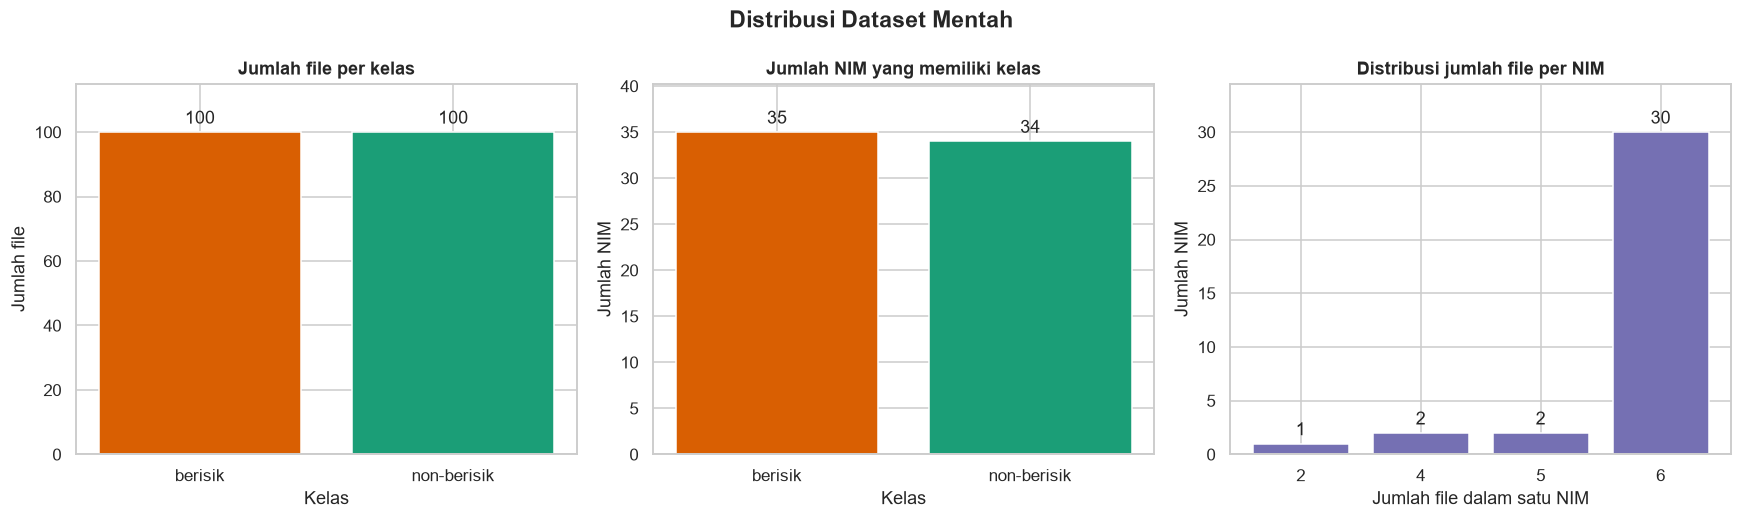

Grafik disimpan: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\02_data_understanding\figures\class_distribution.png
File per kelas: {'berisik': 100, 'non-berisik': 100}
NIM per kelas: {'berisik': 35, 'non-berisik': 34}
NIM dengan 6 file: 30 dari 35


In [9]:
# Tujuan: memvisualisasikan distribusi file, NIM, dan kelengkapan file per NIM.
# Proses: membuat tiga panel grafik dari tabel ringkasan aktual.
# Output: figures/class_distribution.png.

palette = {"berisik": "#D95F02", "non-berisik": "#1B9E77"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

ax = axes[0]
bars = ax.bar(class_summary["label_name"], class_summary["n_files"], color=[palette[x] for x in class_summary["label_name"]])
ax.set_title("Jumlah file per kelas")
ax.set_xlabel("Kelas")
ax.set_ylabel("Jumlah file")
ax.bar_label(bars, padding=3)
ax.margins(y=0.15)

ax = axes[1]
bars = ax.bar(class_summary["label_name"], class_summary["n_nim"], color=[palette[x] for x in class_summary["label_name"]])
ax.set_title("Jumlah NIM yang memiliki kelas")
ax.set_xlabel("Kelas")
ax.set_ylabel("Jumlah NIM")
ax.bar_label(bars, padding=3)
ax.margins(y=0.15)

ax = axes[2]
files_per_nim_counts = nim_summary["n_files"].value_counts().sort_index()
bars = ax.bar(files_per_nim_counts.index.astype(str), files_per_nim_counts.values, color="#7570B3")
ax.set_title("Distribusi jumlah file per NIM")
ax.set_xlabel("Jumlah file dalam satu NIM")
ax.set_ylabel("Jumlah NIM")
ax.bar_label(bars, padding=3)
ax.margins(y=0.15)

fig.suptitle("Distribusi Dataset Mentah", fontsize=15, fontweight="bold")
fig.tight_layout()
figure_path = FIGURE_DIR / "class_distribution.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()

print(f"Grafik disimpan: {figure_path}")
print(f"File per kelas: {dict(zip(class_summary['label_name'], class_summary['n_files']))}")
print(f"NIM per kelas: {dict(zip(class_summary['label_name'], class_summary['n_nim']))}")
print(f"NIM dengan 6 file: {int(nim_summary['lengkap_6_file'].sum())} dari {len(nim_summary)}")

## 10. Distribusi durasi

**Apa yang dilakukan:** menampilkan histogram dan boxplot durasi hasil decode.

**Mengapa:** durasi menentukan apakah crop atau padding diperlukan. Namun pada data ini semua file sudah tepat 30 detik.

**Cara membaca:** grafik sengaja memperlihatkan sebaran yang sangat sempit. Hasil aktual: **200 dari 200 file** berdurasi 30,000 detik (minimum 30.000, maksimum 30.000). Tahap 03 tetap wajib memastikan hasil akhir 480.000 sampel setelah resampling.

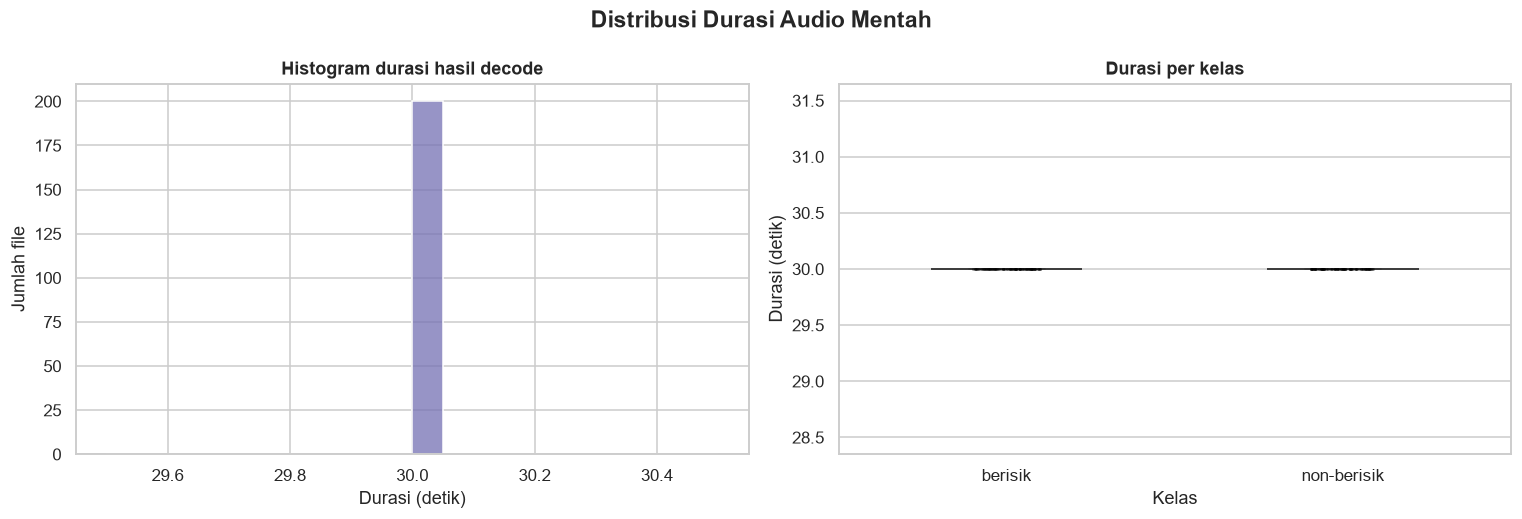

Grafik disimpan: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\02_data_understanding\figures\duration_distribution.png
Durasi minimum: 30.000 detik
Durasi maksimum: 30.000 detik
File tepat 30 detik: 200 dari 200
Durasi di luar toleransi: 0


In [10]:
# Tujuan: menampilkan distribusi durasi hasil decode dan membandingkannya antar kelas.
# Proses: membuat histogram durasi dan boxplot durasi per label dari manifest aktual.
# Output: figures/duration_distribution.png dan ringkasan durasi.

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

ax = axes[0]
sns.histplot(
    data=manifest_raw,
    x="duration_decoded_s",
    bins=20,
    color="#7570B3",
    edgecolor="white",
    ax=ax,
)
ax.set_title("Histogram durasi hasil decode")
ax.set_xlabel("Durasi (detik)")
ax.set_ylabel("Jumlah file")

ax = axes[1]
sns.boxplot(
    data=manifest_raw,
    x="label_name",
    y="duration_decoded_s",
    hue="label_name",
    palette=palette,
    legend=False,
    width=0.45,
    ax=ax,
)
sns.stripplot(
    data=manifest_raw,
    x="label_name",
    y="duration_decoded_s",
    color="black",
    size=2,
    alpha=0.35,
    ax=ax,
)
ax.set_title("Durasi per kelas")
ax.set_xlabel("Kelas")
ax.set_ylabel("Durasi (detik)")

fig.suptitle("Distribusi Durasi Audio Mentah", fontsize=15, fontweight="bold")
fig.tight_layout()
figure_path = FIGURE_DIR / "duration_distribution.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()

duration_stats = manifest_raw["duration_decoded_s"].describe()
print(f"Grafik disimpan: {figure_path}")
print(f"Durasi minimum: {duration_stats['min']:.3f} detik")
print(f"Durasi maksimum: {duration_stats['max']:.3f} detik")
print(f"File tepat 30 detik: {int(manifest_raw['duration_status'].eq('tepat_30_detik').sum())} dari {len(manifest_raw)}")
print(f"Durasi di luar toleransi: {int(manifest_raw['duration_status'].ne('tepat_30_detik').sum())}")

## 11. Karakteristik format

**Apa yang dilakukan:** membandingkan sample rate, jumlah channel, dan estimasi bitrate antar kelas.

**Mengapa:** perbedaan perangkat/encoding dapat menjadi confound. Semua audio harus diseragamkan ke 16 kHz mono sebelum fitur diekstrak.

**Cara membaca:** sample rate aktual: **{'16000': 6, '44100': 69, '48000': 125}**; channel: **{'1': 56, '2': 144}**. Keragaman ini normal untuk data lapangan, tetapi menuntut prosedur konversi yang identik untuk semua file. FFmpeg saat ini: **tidak ditemukan**.

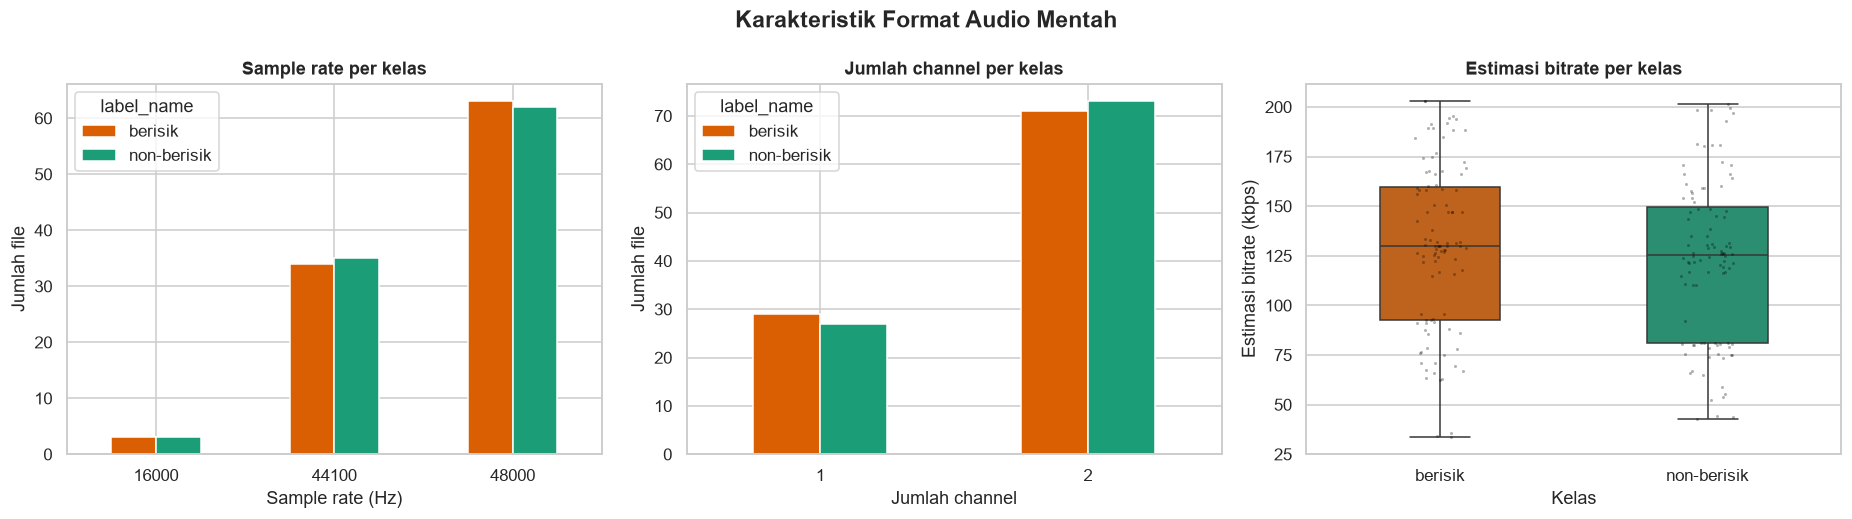

Grafik disimpan: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\02_data_understanding\figures\format_characteristics.png
Format file: {'MP3': 200}
Sample rate: {16000: 6, 44100: 69, 48000: 125}
Channel: {1: 56, 2: 144}


In [11]:
# Tujuan: menampilkan keragaman format teknis audio mentah.
# Proses: membuat grafik sample rate, jumlah channel, dan estimasi bitrate per kelas.
# Output: figures/format_characteristics.png dan ringkasan format.

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

sr_pivot = format_summary.pivot_table(
    index="samplerate", columns="label_name", values="n_files", aggfunc="sum", fill_value=0
)
sr_pivot.plot(kind="bar", ax=axes[0], color=[palette.get(c, "#999999") for c in sr_pivot.columns])
axes[0].set_title("Sample rate per kelas")
axes[0].set_xlabel("Sample rate (Hz)")
axes[0].set_ylabel("Jumlah file")
axes[0].tick_params(axis="x", rotation=0)

ch_pivot = format_summary.pivot_table(
    index="channels", columns="label_name", values="n_files", aggfunc="sum", fill_value=0
)
ch_pivot.plot(kind="bar", ax=axes[1], color=[palette.get(c, "#999999") for c in ch_pivot.columns])
axes[1].set_title("Jumlah channel per kelas")
axes[1].set_xlabel("Jumlah channel")
axes[1].set_ylabel("Jumlah file")
axes[1].tick_params(axis="x", rotation=0)

sns.boxplot(
    data=manifest_raw,
    x="label_name",
    y="bitrate_kbps_estimate",
    hue="label_name",
    palette=palette,
    legend=False,
    width=0.45,
    ax=axes[2],
)
sns.stripplot(
    data=manifest_raw,
    x="label_name",
    y="bitrate_kbps_estimate",
    color="black",
    size=2,
    alpha=0.3,
    ax=axes[2],
)
axes[2].set_title("Estimasi bitrate per kelas")
axes[2].set_xlabel("Kelas")
axes[2].set_ylabel("Estimasi bitrate (kbps)")

fig.suptitle("Karakteristik Format Audio Mentah", fontsize=15, fontweight="bold")
fig.tight_layout()
figure_path = FIGURE_DIR / "format_characteristics.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()

print(f"Grafik disimpan: {figure_path}")
print("Format file:", manifest_raw["format"].value_counts().to_dict())
print("Sample rate:", manifest_raw["samplerate"].value_counts().sort_index().to_dict())
print("Channel:", manifest_raw["channels"].value_counts().sort_index().to_dict())

## 12. Contoh waveform

**Apa yang dilakukan:** memilih file **non-duplikat** pada persentil RMS rendah, tengah, dan tinggi untuk setiap kelas, lalu menampilkan waveform 30 detik setelah dimuat pada 16 kHz mono.

**Mengapa:** waveform membantu melihat variasi amplitudo dan potensi level rendah. Audio 16 kHz mono di sini hanya untuk visualisasi, bukan file final.

**Cara membaca:** judul memuat nama file, NIM, take, dan RMS asli. Perbedaan tinggi gelombang tidak otomatis menunjukkan label; ia menunjukkan perbedaan level dan dinamika. File duplikat dikeluarkan dari pemilihan contoh agar tidak menampilkan salinan.

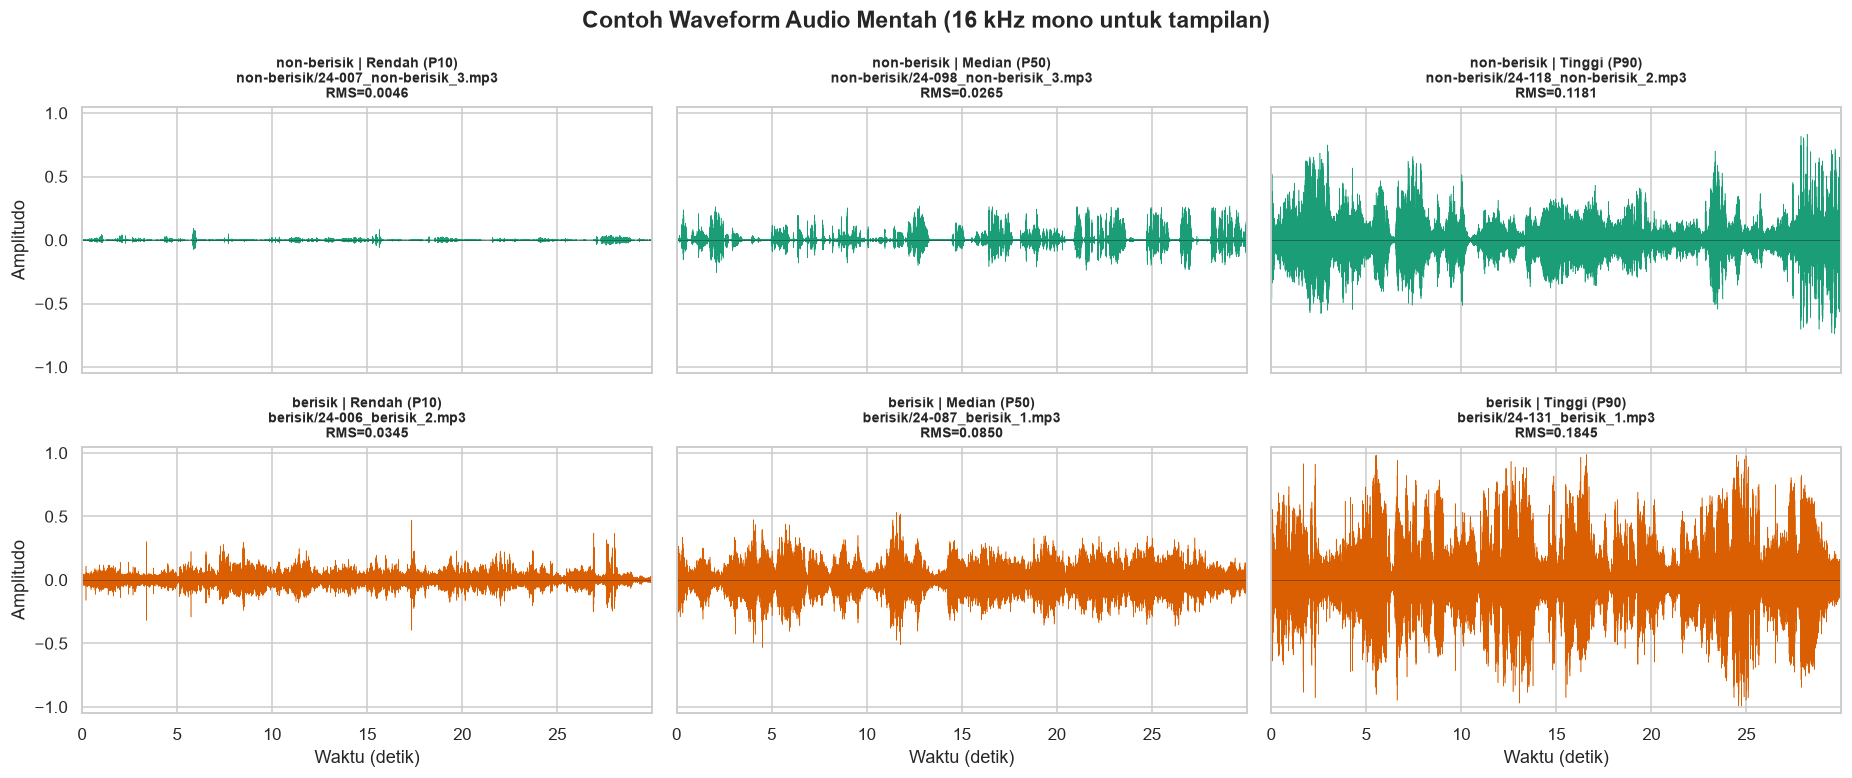

,label_name,level,relative_path,nim,take,rms_native,peak_native,samplerate_native,channels_native
0,non-berisik,Rendah (P10),non-berisik/24-007_non-berisik_3.mp3,24-007,3,0.004560,0.093383,48000,1
1,non-berisik,Median (P50),non-berisik/24-098_non-berisik_3.mp3,24-098,3,0.026513,0.267088,48000,2
2,non-berisik,Tinggi (P90),non-berisik/24-118_non-berisik_2.mp3,24-118,2,0.118115,0.898575,44100,2
3,berisik,Rendah (P10),berisik/24-006_berisik_2.mp3,24-006,2,0.034515,0.478942,44100,2
4,berisik,Median (P50),berisik/24-087_berisik_1.mp3,24-087,1,0.084982,0.712857,44100,2
5,berisik,Tinggi (P90),berisik/24-131_berisik_1.mp3,24-131,1,0.184486,0.995046,48000,2


Grafik disimpan: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\02_data_understanding\figures\waveform_examples.png


In [12]:
# Tujuan: menampilkan contoh waveform dari file asli untuk setiap kelas.
# Proses: memilih file non-duplikat pada persentil RMS rendah/tengah/tinggi, lalu memuat audio pada 16 kHz mono untuk visualisasi.
# Output: figures/waveform_examples.png dan daftar file contoh.

example_rows = []
for label_name in ["non-berisik", "berisik"]:
    candidates = manifest_raw.loc[
        (manifest_raw["label_name"] == label_name) & (~manifest_raw["is_exact_duplicate"])
    ].sort_values("rms").reset_index(drop=True)
    if len(candidates) < 3:
        candidates = manifest_raw.loc[manifest_raw["label_name"] == label_name].sort_values("rms").reset_index(drop=True)

    positions = [round(q * (len(candidates) - 1)) for q in (0.10, 0.50, 0.90)]
    positions = sorted(set(positions))
    while len(positions) < 3 and len(positions) < len(candidates):
        for candidate_position in range(len(candidates)):
            if candidate_position not in positions:
                positions.append(candidate_position)
                break
        positions = sorted(positions)

    for level, position in zip(["Rendah (P10)", "Median (P50)", "Tinggi (P90)"], positions):
        row = candidates.iloc[position]
        example_rows.append(
            {
                "label_name": label_name,
                "level": level,
                "relative_path": row["relative_path"],
                "nim": row["nim"],
                "take": int(row["take"]),
                "rms_native": float(row["rms"]),
                "peak_native": float(row["peak_abs"]),
                "samplerate_native": int(row["samplerate"]),
                "channels_native": int(row["channels"]),
            }
        )

waveform_examples = pd.DataFrame(example_rows)

fig, axes = plt.subplots(2, 3, figsize=(17, 7.2), sharex=True, sharey=True)
for row_index, label_name in enumerate(["non-berisik", "berisik"]):
    subset = waveform_examples.loc[waveform_examples["label_name"] == label_name].reset_index(drop=True)
    for column_index, row in subset.iterrows():
        ax = axes[row_index, column_index]
        path = RAW_DIR / row["relative_path"]
        signal, sr = librosa.load(path, sr=16000, mono=True)
        times = np.arange(len(signal)) / sr
        ax.plot(times, signal, color=palette[label_name], linewidth=0.35)
        ax.axhline(0, color="black", linewidth=0.4, alpha=0.5)
        ax.set_title(
            f"{label_name} | {row['level']}\n{row['relative_path']}\nRMS={row['rms_native']:.4f}",
            fontsize=9,
        )
        ax.set_xlim(0, times[-1] if len(times) else EXPECTED_DURATION_S)
        ax.set_ylim(-1.05, 1.05)
        if row_index == 1:
            ax.set_xlabel("Waktu (detik)")
        if column_index == 0:
            ax.set_ylabel("Amplitudo")

fig.suptitle("Contoh Waveform Audio Mentah (16 kHz mono untuk tampilan)", fontsize=15, fontweight="bold")
fig.tight_layout()
figure_path = FIGURE_DIR / "waveform_examples.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()

display(waveform_examples)
waveform_examples.to_csv(ARTIFACT_DIR / "waveform_example_files.csv", index=False)
print(f"Grafik disimpan: {figure_path}")

## 13. Contoh spektrogram

**Apa yang dilakukan:** menghitung STFT dari file contoh yang sama dengan parameter `n_fft=512`, `win_length=400`, `hop_length=160`, dan window Hann, lalu menampilkan daya dalam dB hingga 8 kHz.

**Mengapa:** spektrogram memperlihatkan distribusi energi terhadap waktu dan frekuensi. Parameter ini juga akan dipakai pada ekstraksi fitur tahap 03, sehingga tampilan EDA konsisten dengan tahap berikutnya.

**Cara membaca:** warna terang berarti daya relatif tinggi. Spektrogram hanya alat eksplorasi; ia bukan fitur model dan tidak dipakai untuk memberi label.

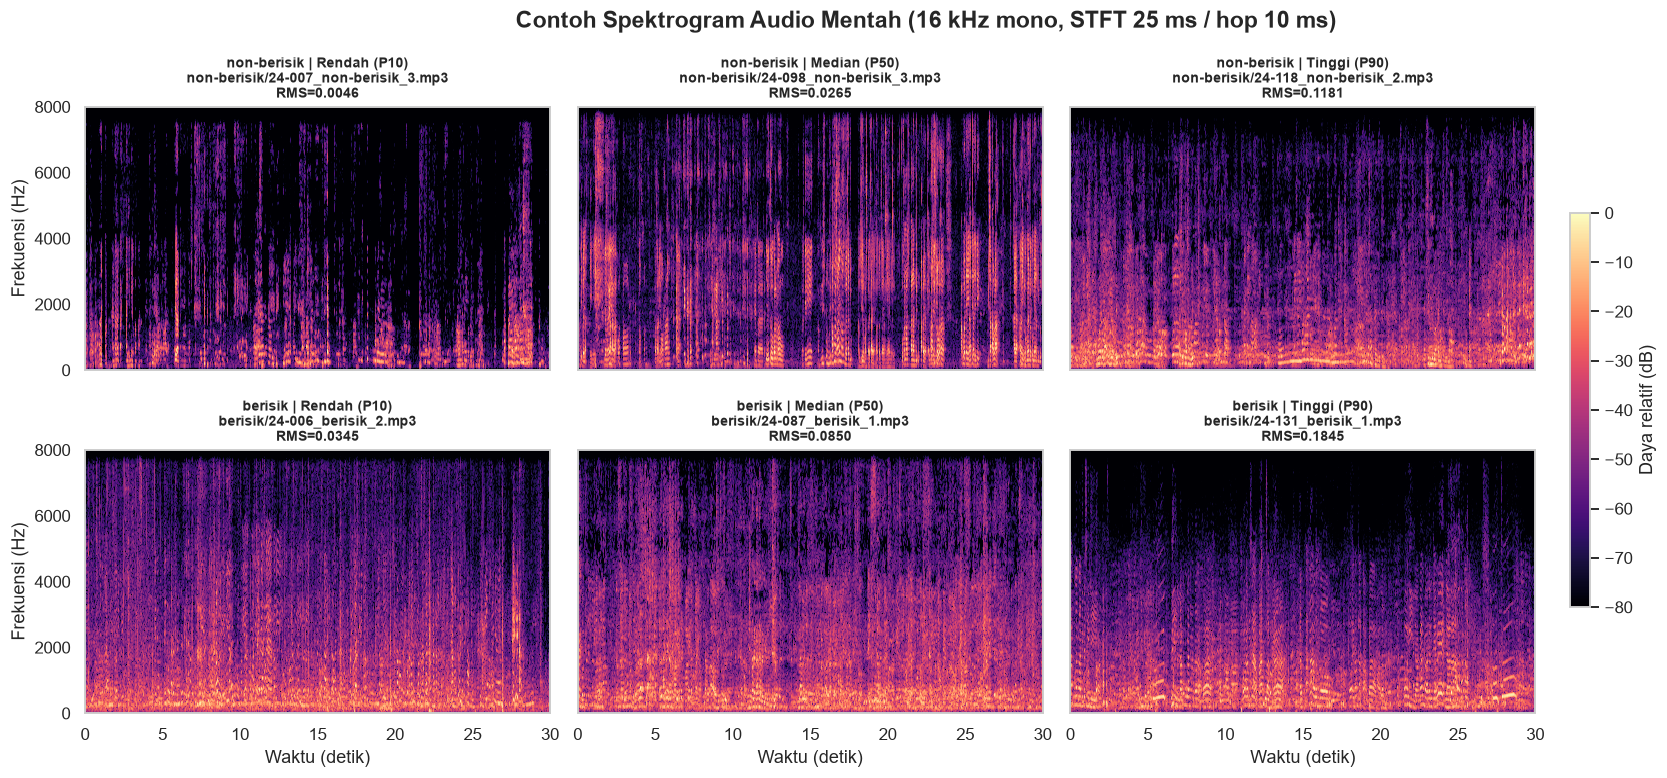

Grafik disimpan: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\02_data_understanding\figures\spectrogram_examples.png


,label_name,level,relative_path,rms_native
0,non-berisik,Rendah (P10),non-berisik/24-007_non-berisik_3.mp3,0.004560
1,non-berisik,Median (P50),non-berisik/24-098_non-berisik_3.mp3,0.026513
2,non-berisik,Tinggi (P90),non-berisik/24-118_non-berisik_2.mp3,0.118115
3,berisik,Rendah (P10),berisik/24-006_berisik_2.mp3,0.034515
4,berisik,Median (P50),berisik/24-087_berisik_1.mp3,0.084982
5,berisik,Tinggi (P90),berisik/24-131_berisik_1.mp3,0.184486


In [13]:
# Tujuan: menampilkan spektrogram contoh audio asli untuk setiap kelas.
# Proses: memakai file contoh yang sama dengan waveform, menghitung STFT 16 kHz, dan menampilkan spektrum daya dalam dB.
# Output: figures/spectrogram_examples.png.

fig, axes = plt.subplots(2, 3, figsize=(17, 7.2), sharex=True, sharey=True)
last_mesh = None
for row_index, label_name in enumerate(["non-berisik", "berisik"]):
    subset = waveform_examples.loc[waveform_examples["label_name"] == label_name].reset_index(drop=True)
    for column_index, row in subset.iterrows():
        ax = axes[row_index, column_index]
        path = RAW_DIR / row["relative_path"]
        signal, sr = librosa.load(path, sr=16000, mono=True)
        stft = librosa.stft(
            signal,
            n_fft=512,
            hop_length=160,
            win_length=400,
            window="hann",
            center=True,
        )
        power = np.abs(stft) ** 2
        power_db = librosa.power_to_db(power, ref=np.max)
        times = librosa.times_like(power, sr=sr, hop_length=160)
        frequencies = librosa.fft_frequencies(sr=sr, n_fft=512)
        last_mesh = ax.pcolormesh(
            times,
            frequencies,
            power_db,
            shading="auto",
            cmap="magma",
            vmin=-80,
            vmax=0,
        )
        ax.set_ylim(0, 8000)
        ax.set_title(
            f"{label_name} | {row['level']}\n{row['relative_path']}\nRMS={row['rms_native']:.4f}",
            fontsize=9,
        )
        if row_index == 1:
            ax.set_xlabel("Waktu (detik)")
        if column_index == 0:
            ax.set_ylabel("Frekuensi (Hz)")

fig.suptitle("Contoh Spektrogram Audio Mentah (16 kHz mono, STFT 25 ms / hop 10 ms)", fontsize=15, fontweight="bold")
fig.tight_layout()
if last_mesh is not None:
    colorbar = fig.colorbar(last_mesh, ax=axes.ravel().tolist(), shrink=0.65, pad=0.02)
    colorbar.set_label("Daya relatif (dB)")
figure_path = FIGURE_DIR / "spectrogram_examples.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()

print(f"Grafik disimpan: {figure_path}")
display(waveform_examples[["label_name", "level", "relative_path", "rms_native"]])

## 14. Temuan kualitas berprioritas

**Apa yang dilakukan:** menggabungkan seluruh pemeriksaan menjadi daftar temuan dengan severity, implikasi, dan tindakan untuk tahap 03.

**Mengapa:** temuan harus dapat ditindaklanjuti, bukan hanya berupa angka. Prioritas tertinggi adalah hal yang dapat membatalkan validitas evaluasi.

**Cara membaca:** urutan severity: Kritis → Tinggi → Sedang → Rendah → Info. Temuan kritis pada data ini adalah **duplikasi lintas NIM** dan **konflik label**. Keduanya harus diselesaikan sebelum split/modeling. Hasil lengkap tersimpan di `quality_findings.csv`.

In [14]:
# Tujuan: merangkum temuan kualitas data menjadi daftar yang dapat ditindaklanjuti.
# Proses: menggabungkan hasil inventaris, validasi identitas, duplikasi, integritas, dan metadata aktual.
# Output: quality_findings.csv dan tabel temuan berprioritas.

cross_nim_rows = manifest_raw.loc[manifest_raw["duplicate_scope"] == "cross_nim"]
cross_nim_nims = sorted(cross_nim_rows["nim"].dropna().unique().tolist())
cross_label_rows = manifest_raw.loc[manifest_raw["duplicate_scope"] == "cross_label"]
cross_label_detail = "; ".join(
    sorted(
        f"{row.duplicate_group_id}: {row.files}"
        for row in duplicate_groups.loc[duplicate_groups["scope"] == "cross_label"].itertuples()
    )
)
incomplete_nims = nim_summary.loc[~nim_summary["lengkap_6_file"], "nim"].tolist()
single_class_nims = nim_summary.loc[~nim_summary["memiliki_dua_kelas"], "nim"].tolist()
low_level_paths = "; ".join(low_level_files["relative_path"].tolist())

findings = [
    {
        "finding_id": "F01",
        "kategori": "Duplikasi",
        "temuan": (
            f"{len(duplicate_groups)} grup duplikat eksak melibatkan "
            f"{int(manifest_raw['is_exact_duplicate'].sum())} file; hanya "
            f"{manifest_raw['sha256'].nunique()} hash unik dari {len(manifest_raw)} file."
        ),
        "jumlah": int(manifest_raw["is_exact_duplicate"].sum()),
        "severity": "Tinggi",
        "implikasi": "File kembar tidak menambah informasi baru dan dapat membocorkan konten antar-split.",
        "tindakan_03": "Tinjau setiap grup; jangan langsung hapus; putuskan representasi dan karantina secara eksplisit.",
    },
    {
        "finding_id": "F02",
        "kategori": "Duplikasi lintas NIM",
        "temuan": (
            f"{int((duplicate_groups['scope'] == 'cross_nim').sum())} grup duplikat eksak melintasi NIM "
            f"({len(cross_nim_rows)} file; NIM: {', '.join(cross_nim_nims)})."
        ),
        "jumlah": int(len(cross_nim_rows)),
        "severity": "Kritis",
        "implikasi": (
            "GroupKFold berbasis NIM tidak mencegah kebocoran bila audio identik muncul pada NIM berbeda; "
            "konten yang sama dapat masuk train dan test."
        ),
        "tindakan_03": "Selesaikan duplikasi lintas NIM sebelum split; jangan mengandalkan GroupKFold saja.",
    },
    {
        "finding_id": "F03",
        "kategori": "Konflik label",
        "temuan": (
            f"{int((duplicate_groups['scope'] == 'cross_label').sum())} grup duplikat eksak memiliki label berbeda: "
            f"{cross_label_detail}."
        ),
        "jumlah": int(len(cross_label_rows)),
        "severity": "Kritis",
        "implikasi": "Dua file identik tidak mungkin memiliki label ground truth yang berbeda; minimal satu label salah.",
        "tindakan_03": "Karantina atau minta adjudikasi manusia; jangan memakai keduanya sebagai dua kelas.",
    },
    {
        "finding_id": "F04",
        "kategori": "Duplikasi dalam NIM",
        "temuan": (
            f"{int((duplicate_groups['scope'] == 'within_nim').sum())} grup duplikat berada dalam NIM yang sama "
            "dan mencakup beberapa take sekaligus."
        ),
        "jumlah": int((manifest_raw["duplicate_scope"] == "within_nim").sum()),
        "severity": "Tinggi",
        "implikasi": "Take yang seharusnya berbeda ternyata rekaman identik; jumlah sampel efektif lebih kecil dari 200.",
        "tindakan_03": "Perlakukan take kembar sebagai satu observasi atau karantina sesuai kebijakan yang terdokumentasi.",
    },
    {
        "finding_id": "F05",
        "kategori": "Kelengkapan NIM",
        "temuan": (
            f"{len(incomplete_nims)} NIM tidak memiliki 6 file: {', '.join(incomplete_nims)}; "
            f"{len(missing_takes)} kombinasi NIM-kelas-take hilang."
        ),
        "jumlah": int(len(missing_takes)),
        "severity": "Sedang",
        "implikasi": "Protokol 3 take per kelas tidak terpenuhi untuk sebagian NIM; data tidak seimbang per subjek.",
        "tindakan_03": "Pertahankan identitas apa adanya, tandai NIM tidak lengkap, dan putuskan inklusi dengan kriteria eksplisit.",
    },
    {
        "finding_id": "F06",
        "kategori": "NIM satu kelas",
        "temuan": (
            f"{len(single_class_nims)} NIM hanya memiliki satu kelas: {', '.join(single_class_nims)}."
        ),
        "jumlah": int(len(single_class_nims)),
        "severity": "Sedang",
        "implikasi": "NIM tersebut tidak dapat berkontribusi pada kedua kelas dan dapat memengaruhi kestabilan evaluasi.",
        "tindakan_03": "Putuskan apakah tetap dipakai; jika dipakai, laporkan komposisinya dan jangan menyembunyikan keterbatasan.",
    },
    {
        "finding_id": "F07",
        "kategori": "Integritas file",
        "temuan": (
            f"{int((~manifest_raw['read_ok'].fillna(False)).sum())} file gagal dibaca, "
            f"{int(manifest_raw['all_zero'].sum())} sinyal semua nol, "
            f"{int(manifest_raw['nan_count'].fillna(0).gt(0).sum())} file ber-NaN, "
            f"{int(manifest_raw['inf_count'].fillna(0).gt(0).sum())} file ber-Inf."
        ),
        "jumlah": int(manifest_raw["critical_failure"].sum()),
        "severity": "Info",
        "implikasi": "Tidak ada kerusakan teknis yang terdeteksi pada tahap ini.",
        "tindakan_03": "Tetap jalankan pemeriksaan ulang setelah konversi dan setelah ekstraksi fitur.",
    },
    {
        "finding_id": "F08",
        "kategori": "Durasi",
        "temuan": (
            f"{int(manifest_raw['duration_status'].eq('tepat_30_detik').sum())} dari {len(manifest_raw)} file "
            f"berdurasi tepat 30 detik (min={manifest_raw['duration_decoded_s'].min():.3f}, "
            f"max={manifest_raw['duration_decoded_s'].max():.3f})."
        ),
        "jumlah": int(manifest_raw["duration_status"].eq("tepat_30_detik").sum()),
        "severity": "Info",
        "implikasi": "Pada data mentah tidak ada kebutuhan crop/pad karena durasi; aturan tetap wajib diterapkan setelah resampling.",
        "tindakan_03": "Pastikan hasil akhir tepat 480.000 sampel dan catat tindakan aktual per file.",
    },
    {
        "finding_id": "F09",
        "kategori": "Heterogenitas format",
        "temuan": (
            f"Sample rate: {manifest_raw['samplerate'].value_counts().sort_index().to_dict()}; "
            f"channel: {manifest_raw['channels'].value_counts().sort_index().to_dict()}."
        ),
        "jumlah": int(manifest_raw["samplerate"].nunique()),
        "severity": "Sedang",
        "implikasi": "Audio belum seragam; ekstraksi fitur harus dilakukan setelah konversi ke 16 kHz mono.",
        "tindakan_03": "Resample ke 16 kHz, downmix mono, dan validasi 480.000 sampel.",
    },
    {
        "finding_id": "F10",
        "kategori": "Level sinyal",
        "temuan": (
            f"{int(manifest_raw['low_level'].sum())} file memiliki peak < {LOW_PEAK_THRESHOLD:.2f}: "
            f"{low_level_paths if low_level_paths else 'tidak ada'}."
        ),
        "jumlah": int(manifest_raw["low_level"].sum()),
        "severity": "Rendah",
        "implikasi": "Peak normalization akan memperkuat sinyal dan noise floor secara bersamaan.",
        "tindakan_03": "Audit level dan dengarkan file tersebut; jangan menghapus hanya karena levelnya rendah.",
    },
    {
        "finding_id": "F11",
        "kategori": "Overshoot MP3",
        "temuan": f"{int(manifest_raw['peak_over_one'].fillna(False).sum())} file memiliki peak > 1.0 setelah decode.",
        "jumlah": int(manifest_raw["peak_over_one"].fillna(False).sum()),
        "severity": "Rendah",
        "implikasi": "Nilai > 1.0 dapat muncul dari decoding MP3 dan bukan bukti file rusak.",
        "tindakan_03": "Peak normalization wajib menangani nilai absolut > 1.0 dan sinyal nol.",
    },
    {
        "finding_id": "F12",
        "kategori": "Label",
        "temuan": (
            f"Label folder dan nama file cocok untuk {int(manifest_raw['label_match'].sum())} file; "
            "namun kecocokan ini hanya konsistensi metadata, bukan verifikasi isi audio."
        ),
        "jumlah": int(manifest_raw["label_match"].sum()),
        "severity": "Sedang",
        "implikasi": "Label semantik belum tentu benar; duplikat lintas label sudah membuktikan adanya konflik.",
        "tindakan_03": "Pertahankan label yang dapat dilacak; karantina kasus konflik; jangan memberi label baru dari kemiripan audio.",
    },
    {
        "finding_id": "F13",
        "kategori": "Lingkungan",
        "temuan": f"FFmpeg di PATH: {shutil.which('ffmpeg') or 'tidak ditemukan'}.",
        "jumlah": 0 if shutil.which("ffmpeg") else 1,
        "severity": "Sedang" if not shutil.which("ffmpeg") else "Info",
        "implikasi": "Konversi MP3 pada Data Preparation memerlukan FFmpeg yang dapat dipanggil.",
        "tindakan_03": "Pasang/daftarkan FFmpeg sebelum menjalankan konversi.",
    },
    {
        "finding_id": "F14",
        "kategori": "Keseimbangan kelas",
        "temuan": (
            f"Data mentah: {dict(zip(class_summary['label_name'], class_summary['n_files']))}; "
            f"setelah duplikasi dan karantina, komposisi harus dihitung ulang."
        ),
        "jumlah": int(len(manifest_raw)),
        "severity": "Info",
        "implikasi": "Keseimbangan 100/100 pada data mentah tidak otomatis bertahan setelah pembersihan.",
        "tindakan_03": "Laporkan distribusi final dan pertimbangkan class_weight di dalam pipeline bila perlu.",
    },
]

quality_findings = pd.DataFrame(findings)
severity_order = {"Kritis": 0, "Tinggi": 1, "Sedang": 2, "Rendah": 3, "Info": 4}
quality_findings["severity_order"] = quality_findings["severity"].map(severity_order)
quality_findings = quality_findings.sort_values(["severity_order", "finding_id"]).drop(columns="severity_order")

display(quality_findings[["finding_id", "kategori", "severity", "jumlah", "temuan"]])
quality_findings.to_csv(ARTIFACT_DIR / "quality_findings.csv", index=False)
print(f"Temuan kualitas disimpan: {ARTIFACT_DIR / 'quality_findings.csv'} ({len(quality_findings)} temuan)")

,finding_id,kategori,severity,jumlah,temuan
1,F02,Duplikasi lintas NIM,Kritis,30,14 grup duplikat eksak melintasi NIM (30 file;...
2,F03,Konflik label,Kritis,2,1 grup duplikat eksak memiliki label berbeda: ...
0,F01,Duplikasi,Tinggi,41,18 grup duplikat eksak melibatkan 41 file; han...
3,F04,Duplikasi dalam NIM,Tinggi,9,3 grup duplikat berada dalam NIM yang sama dan...
4,F05,Kelengkapan NIM,Sedang,10,"5 NIM tidak memiliki 6 file: 24-003, 24-053, 2..."
5,F06,NIM satu kelas,Sedang,1,1 NIM hanya memiliki satu kelas: 24-123.
8,F09,Heterogenitas format,Sedang,3,"Sample rate: {16000: 6, 44100: 69, 48000: 125}..."
11,F12,Label,Sedang,200,Label folder dan nama file cocok untuk 200 fil...
12,F13,Lingkungan,Sedang,1,FFmpeg di PATH: tidak ditemukan.
9,F10,Level sinyal,Rendah,3,3 file memiliki peak < 0.05: non-berisik/24-00...


Temuan kualitas disimpan: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\02_data_understanding\quality_findings.csv (14 temuan)


## 15. Validasi artefak dan laporan

**Apa yang dilakukan:** memastikan inventaris sama dengan jumlah file mentah, manifest lengkap, path unik, metadata terbaca, identitas terisi, grup duplikat konsisten, tidak ada kegagalan kritis, dan semua grafik tersedia. Cell ini juga menulis laporan Markdown.

**Mengapa:** tahap 03 tidak boleh dimulai jika artefak Data Understanding tidak dapat dipertanggungjawabkan.

**Cara membaca:** semua baris validasi harus **LULUS**. Laporan lengkap tersimpan di `artifacts/02_data_understanding/data_understanding_report.md`.

In [15]:
# Tujuan: memvalidasi keterhubungan seluruh artefak Data Understanding dan menulis laporan ringkas.
# Proses: memeriksa jumlah baris, keunikan path, kelengkapan metadata, konsistensi kelas, dan keberadaan grafik.
# Output: laporan validasi, manifest final Data Understanding, dan data_understanding_report.md.

from IPython.display import Markdown


def df_to_markdown(frame, max_rows=20):
    display_frame = frame.head(max_rows).copy()
    columns = [str(column) for column in display_frame.columns]
    lines = [
        "| " + " | ".join(columns) + " |",
        "|" + "|".join(["---"] * len(columns)) + "|",
    ]
    for row in display_frame.itertuples(index=False):
        values = []
        for value in row:
            if isinstance(value, float):
                text = f"{value:.4f}"
            else:
                text = str(value)
            values.append(text.replace("|", "\\|").replace("\n", " "))
        lines.append("| " + " | ".join(values) + " |")
    if len(frame) > max_rows:
        lines.append(f"\n*Menampilkan {max_rows} dari {len(frame)} baris.*")
    return "\n".join(lines)


raw_file_count = sum(1 for path in RAW_DIR.rglob("*") if path.is_file())
figure_paths = [
    FIGURE_DIR / "class_distribution.png",
    FIGURE_DIR / "duration_distribution.png",
    FIGURE_DIR / "format_characteristics.png",
    FIGURE_DIR / "waveform_examples.png",
    FIGURE_DIR / "spectrogram_examples.png",
]

assert len(inventory) == raw_file_count, "Jumlah inventaris tidak sama dengan jumlah file mentah."
assert len(manifest_raw) == len(inventory), "Manifest tidak mencakup seluruh inventaris."
assert manifest_raw["relative_path"].is_unique, "Ada relative_path duplikat pada manifest."
assert manifest_raw["read_ok"].fillna(False).all(), "Ada file yang gagal dibaca."
assert manifest_raw["sha256"].notna().all(), "Ada file tanpa hash."
assert manifest_raw["nim"].notna().all(), "Ada NIM yang tidak terbaca."
assert manifest_raw["take"].notna().all(), "Ada take yang tidak terbaca."
assert manifest_raw["label"].notna().all(), "Ada label yang tidak dapat dipastikan."
assert len(duplicate_files) == int(manifest_raw["is_exact_duplicate"].sum()), "Jumlah file duplikat tidak konsisten."
assert int(duplicate_groups["n_files"].sum()) == len(duplicate_files), "Ukuran grup duplikat tidak konsisten."
assert manifest_raw["critical_failure"].sum() == 0, "Ada kegagalan integritas kritis."
assert all(path.exists() for path in figure_paths), "Ada grafik yang belum dihasilkan."
assert (ARTIFACT_DIR / "data_understanding_summary.json").exists(), "Ringkasan JSON belum dibuat."

manifest_raw.to_csv(ARTIFACT_DIR / "manifest_raw.csv", index=False)

report = f"""# 02 — Data Understanding: Laporan Aktual

## Ringkasan data

- Total file mentah: **{len(manifest_raw)}**
- NIM unik: **{manifest_raw['nim'].nunique()}**
- Kelas berisik: **{int((manifest_raw['label'] == 1).sum())} file**
- Kelas non-berisik: **{int((manifest_raw['label'] == 0).sum())} file**
- File berdurasi tepat 30 detik: **{int(manifest_raw['duration_status'].eq('tepat_30_detik').sum())} / {len(manifest_raw)}**
- File berhasil dibaca: **{int(manifest_raw['read_ok'].fillna(False).sum())} / {len(manifest_raw)}**
- Hash unik: **{manifest_raw['sha256'].nunique()}**
- File terlibat duplikat eksak: **{int(manifest_raw['is_exact_duplicate'].sum())}**
- NIM lengkap 6 file: **{int(nim_summary['lengkap_6_file'].sum())} / {len(nim_summary)}**
- Kombinasi NIM-kelas-take yang hilang: **{len(missing_takes)}**

## Distribusi kelas

{df_to_markdown(class_summary)}

## Kelengkapan per NIM

{df_to_markdown(nim_summary, max_rows=40)}

## Format dan metadata

{df_to_markdown(format_summary)}

{df_to_markdown(metadata_summary)}

## Duplikasi eksak

{df_to_markdown(duplicate_groups[['duplicate_group_id', 'n_files', 'labels', 'nims', 'takes', 'scope']])}

Interpretasi:

- **{int((duplicate_groups['scope'] == 'cross_label').sum())} grup** memiliki label berbeda untuk audio identik. Ini adalah konflik label yang harus dikarantina atau diadjudikasi.
- **{int((duplicate_groups['scope'] == 'cross_nim').sum())} grup** melintasi NIM. `GroupKFold` saja **tidak** mencegah kebocoran untuk kasus ini karena konten identik dapat muncul pada NIM train dan test.
- **{int((duplicate_groups['scope'] == 'within_nim').sum())} grup** berada dalam NIM yang sama dan mencakup beberapa take, sehingga take tersebut bukan observasi independen.

## Temuan kualitas berprioritas

{df_to_markdown(quality_findings[['finding_id', 'kategori', 'severity', 'jumlah', 'temuan', 'tindakan_03']], max_rows=40)}

## Artefak

- `inventory_raw.csv`: inventaris awal.
- `manifest_raw.csv`: manifest mentah terpadu.
- `audio_metadata.csv`: metadata sinyal per file.
- `duplicate_groups.csv`, `duplicate_files.csv`: hasil deteksi duplikat.
- `missing_takes.csv`: kombinasi NIM-kelas-take yang tidak ada.
- `class_summary.csv`, `nim_summary.csv`, `format_summary.csv`, `metadata_summary.csv`.
- `quality_findings.csv`: temuan yang harus ditindaklanjuti pada tahap 03.
- `data_understanding_summary.json`: ringkasan untuk otomasi.
- `figures/`: distribusi kelas, durasi, format, waveform, dan spektrogram.

## Kesimpulan

Data mentah berjumlah **{len(manifest_raw)} file** dan **{manifest_raw['nim'].nunique()} NIM**, dengan distribusi kelas **{int((manifest_raw['label'] == 1).sum())} berisik** dan **{int((manifest_raw['label'] == 0).sum())} non-berisik**. Semua file dapat dibaca dan berdurasi 30 detik, tetapi dataset **belum siap dimodelkan** karena terdapat duplikasi eksak—termasuk duplikasi lintas NIM dan satu konflik label—serta {len(incomplete_nims)} NIM yang tidak lengkap. Keputusan pembersihan, karantina, dan seleksi data harus dilakukan pada tahap 03 dengan ketertelusuran penuh. FFmpeg di PATH: **{shutil.which('ffmpeg') or 'tidak ditemukan'}**.
"""

report_path = ARTIFACT_DIR / "data_understanding_report.md"
report_path.write_text(report, encoding="utf-8")

validation_summary = pd.DataFrame(
    {
        "pemeriksaan": [
            "inventaris = jumlah file mentah",
            "manifest = inventaris",
            "relative_path unik",
            "semua file terbaca",
            "semua NIM/take/label terisi",
            "konsistensi grup duplikat",
            "tidak ada kegagalan kritis",
            "semua grafik tersedia",
            "laporan Markdown tersedia",
        ],
        "status": [
            "LULUS",
            "LULUS",
            "LULUS",
            "LULUS",
            "LULUS",
            "LULUS",
            "LULUS",
            "LULUS",
            "LULUS",
        ],
    }
)

display(validation_summary)
print("VALIDASI 02: LULUS")
print(f"Laporan disimpan: {report_path}")
display(Markdown(report))

,pemeriksaan,status
0,inventaris = jumlah file mentah,LULUS
1,manifest = inventaris,LULUS
2,relative_path unik,LULUS
3,semua file terbaca,LULUS
4,semua NIM/take/label terisi,LULUS
5,konsistensi grup duplikat,LULUS
6,tidak ada kegagalan kritis,LULUS
7,semua grafik tersedia,LULUS
8,laporan Markdown tersedia,LULUS


VALIDASI 02: LULUS
Laporan disimpan: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\02_data_understanding\data_understanding_report.md


# 02 — Data Understanding: Laporan Aktual

## Ringkasan data

- Total file mentah: **200**
- NIM unik: **35**
- Kelas berisik: **100 file**
- Kelas non-berisik: **100 file**
- File berdurasi tepat 30 detik: **200 / 200**
- File berhasil dibaca: **200 / 200**
- Hash unik: **177**
- File terlibat duplikat eksak: **41**
- NIM lengkap 6 file: **30 / 35**
- Kombinasi NIM-kelas-take yang hilang: **10**

## Distribusi kelas

| label_name | n_files | n_nim | n_unique_hashes | n_duplicate_files | n_low_level | duration_min_s | duration_max_s | size_median_mb | peak_median | rms_median |
|---|---|---|---|---|---|---|---|---|---|---|
| berisik | 100 | 35 | 89 | 21 | 0 | 30.0000 | 30.0000 | 0.4649 | 0.8900 | 0.0858 |
| non-berisik | 100 | 34 | 89 | 20 | 3 | 30.0000 | 30.0000 | 0.4487 | 0.3957 | 0.0262 |

## Kelengkapan per NIM

| nim | n_berisik | n_non_berisik | n_files | n_unique_hashes | n_duplicate_files | lengkap_6_file | memiliki_dua_kelas |
|---|---|---|---|---|---|---|---|
| 24-003 | 3 | 2 | 5 | 5 | 5 | False | True |
| 24-006 | 3 | 3 | 6 | 6 | 0 | True | True |
| 24-007 | 3 | 3 | 6 | 6 | 0 | True | True |
| 24-026 | 3 | 3 | 6 | 6 | 0 | True | True |
| 24-027 | 3 | 3 | 6 | 6 | 0 | True | True |
| 24-031 | 3 | 3 | 6 | 6 | 3 | True | True |
| 24-034 | 3 | 3 | 6 | 5 | 2 | True | True |
| 24-053 | 2 | 3 | 5 | 5 | 2 | False | True |
| 24-068 | 3 | 3 | 6 | 6 | 0 | True | True |
| 24-071 | 3 | 3 | 6 | 6 | 6 | True | True |
| 24-078 | 3 | 3 | 6 | 4 | 3 | True | True |
| 24-079 | 3 | 3 | 6 | 6 | 3 | True | True |
| 24-081 | 3 | 3 | 6 | 6 | 0 | True | True |
| 24-087 | 3 | 3 | 6 | 6 | 0 | True | True |
| 24-098 | 3 | 3 | 6 | 6 | 3 | True | True |
| 24-100 | 3 | 3 | 6 | 6 | 0 | True | True |
| 24-101 | 3 | 3 | 6 | 6 | 0 | True | True |
| 24-115 | 3 | 3 | 6 | 6 | 3 | True | True |
| 24-118 | 3 | 3 | 6 | 6 | 0 | True | True |
| 24-119 | 3 | 3 | 6 | 6 | 0 | True | True |
| 24-123 | 2 | 0 | 2 | 2 | 2 | False | False |
| 24-125 | 3 | 3 | 6 | 6 | 0 | True | True |
| 24-131 | 3 | 3 | 6 | 6 | 0 | True | True |
| 24-137 | 3 | 3 | 6 | 6 | 0 | True | True |
| 24-141 | 3 | 3 | 6 | 6 | 0 | True | True |
| 24-145 | 3 | 3 | 6 | 6 | 0 | True | True |
| 24-157 | 3 | 3 | 6 | 4 | 3 | True | True |
| 24-168 | 3 | 3 | 6 | 6 | 0 | True | True |
| 24-169 | 1 | 3 | 4 | 4 | 0 | False | True |
| 24-179 | 3 | 3 | 6 | 6 | 0 | True | True |
| 24-190 | 3 | 3 | 6 | 6 | 2 | True | True |
| 24-196 | 3 | 3 | 6 | 4 | 3 | True | True |
| 24-201 | 3 | 3 | 6 | 6 | 1 | True | True |
| 24-202 | 3 | 3 | 6 | 6 | 0 | True | True |
| 24-228 | 2 | 2 | 4 | 4 | 0 | False | True |

## Format dan metadata

| label_name | samplerate | channels | n_files |
|---|---|---|---|
| berisik | 16000 | 1 | 3 |
| berisik | 44100 | 2 | 34 |
| berisik | 48000 | 1 | 26 |
| berisik | 48000 | 2 | 37 |
| non-berisik | 16000 | 1 | 3 |
| non-berisik | 44100 | 2 | 35 |
| non-berisik | 48000 | 1 | 24 |
| non-berisik | 48000 | 2 | 38 |

| metrik | count | mean | std | min | 25% | 50% | 75% | max |
|---|---|---|---|---|---|---|---|---|
| duration_decoded_s | 200.0000 | 30.0000 | 0.0000 | 30.0000 | 30.0000 | 30.0000 | 30.0000 | 30.0000 |
| size_mb | 200.0000 | 0.4496 | 0.1468 | 0.1197 | 0.3251 | 0.4569 | 0.5646 | 0.7267 |
| bitrate_kbps_estimate | 200.0000 | 125.7221 | 41.0441 | 33.4680 | 90.8920 | 127.7525 | 157.8816 | 203.1939 |
| peak_abs | 200.0000 | 0.6420 | 0.3477 | 0.0220 | 0.3649 | 0.6743 | 0.9204 | 1.5118 |
| rms | 200.0000 | 0.0738 | 0.0693 | 0.0012 | 0.0234 | 0.0502 | 0.1135 | 0.3144 |

## Duplikasi eksak

| duplicate_group_id | n_files | labels | nims | takes | scope |
|---|---|---|---|---|---|
| DUP01 | 2 | berisik | 24-003, 24-053 | 1, 3 | cross_nim |
| DUP02 | 2 | berisik | 24-003, 24-079 | 2 | cross_nim |
| DUP03 | 3 | berisik | 24-003, 24-079, 24-123 | 1, 3 | cross_nim |
| DUP04 | 2 | non-berisik, berisik | 24-034 | 1 | cross_label |
| DUP05 | 2 | berisik | 24-071, 24-098 | 1 | cross_nim |
| DUP06 | 2 | berisik | 24-071, 24-098 | 2 | cross_nim |
| DUP07 | 2 | berisik | 24-071, 24-098 | 3 | cross_nim |
| DUP08 | 2 | berisik | 24-115, 24-190 | 3 | cross_nim |
| DUP09 | 2 | berisik | 24-123, 24-201 | 1, 2 | cross_nim |
| DUP10 | 3 | berisik | 24-157 | 1, 2, 3 | within_nim |
| DUP11 | 2 | non-berisik | 24-003, 24-053 | 1, 2 | cross_nim |
| DUP12 | 2 | non-berisik | 24-003, 24-079 | 1, 3 | cross_nim |
| DUP13 | 2 | non-berisik | 24-031, 24-071 | 1, 3 | cross_nim |
| DUP14 | 3 | non-berisik | 24-031, 24-071, 24-115 | 2 | cross_nim |
| DUP15 | 2 | non-berisik | 24-031, 24-071 | 1, 3 | cross_nim |
| DUP16 | 3 | non-berisik | 24-078 | 1, 2, 3 | within_nim |
| DUP17 | 2 | non-berisik | 24-115, 24-190 | 1, 3 | cross_nim |
| DUP18 | 3 | non-berisik | 24-196 | 1, 2, 3 | within_nim |

Interpretasi:

- **1 grup** memiliki label berbeda untuk audio identik. Ini adalah konflik label yang harus dikarantina atau diadjudikasi.
- **14 grup** melintasi NIM. `GroupKFold` saja **tidak** mencegah kebocoran untuk kasus ini karena konten identik dapat muncul pada NIM train dan test.
- **3 grup** berada dalam NIM yang sama dan mencakup beberapa take, sehingga take tersebut bukan observasi independen.

## Temuan kualitas berprioritas

| finding_id | kategori | severity | jumlah | temuan | tindakan_03 |
|---|---|---|---|---|---|
| F02 | Duplikasi lintas NIM | Kritis | 30 | 14 grup duplikat eksak melintasi NIM (30 file; NIM: 24-003, 24-031, 24-053, 24-071, 24-079, 24-098, 24-115, 24-123, 24-190, 24-201). | Selesaikan duplikasi lintas NIM sebelum split; jangan mengandalkan GroupKFold saja. |
| F03 | Konflik label | Kritis | 2 | 1 grup duplikat eksak memiliki label berbeda: DUP04: berisik/24-034_berisik_1.mp3 \| non-berisik/24-034_non-berisik_1.mp3. | Karantina atau minta adjudikasi manusia; jangan memakai keduanya sebagai dua kelas. |
| F01 | Duplikasi | Tinggi | 41 | 18 grup duplikat eksak melibatkan 41 file; hanya 177 hash unik dari 200 file. | Tinjau setiap grup; jangan langsung hapus; putuskan representasi dan karantina secara eksplisit. |
| F04 | Duplikasi dalam NIM | Tinggi | 9 | 3 grup duplikat berada dalam NIM yang sama dan mencakup beberapa take sekaligus. | Perlakukan take kembar sebagai satu observasi atau karantina sesuai kebijakan yang terdokumentasi. |
| F05 | Kelengkapan NIM | Sedang | 10 | 5 NIM tidak memiliki 6 file: 24-003, 24-053, 24-123, 24-169, 24-228; 10 kombinasi NIM-kelas-take hilang. | Pertahankan identitas apa adanya, tandai NIM tidak lengkap, dan putuskan inklusi dengan kriteria eksplisit. |
| F06 | NIM satu kelas | Sedang | 1 | 1 NIM hanya memiliki satu kelas: 24-123. | Putuskan apakah tetap dipakai; jika dipakai, laporkan komposisinya dan jangan menyembunyikan keterbatasan. |
| F09 | Heterogenitas format | Sedang | 3 | Sample rate: {16000: 6, 44100: 69, 48000: 125}; channel: {1: 56, 2: 144}. | Resample ke 16 kHz, downmix mono, dan validasi 480.000 sampel. |
| F12 | Label | Sedang | 200 | Label folder dan nama file cocok untuk 200 file; namun kecocokan ini hanya konsistensi metadata, bukan verifikasi isi audio. | Pertahankan label yang dapat dilacak; karantina kasus konflik; jangan memberi label baru dari kemiripan audio. |
| F13 | Lingkungan | Sedang | 1 | FFmpeg di PATH: tidak ditemukan. | Pasang/daftarkan FFmpeg sebelum menjalankan konversi. |
| F10 | Level sinyal | Rendah | 3 | 3 file memiliki peak < 0.05: non-berisik/24-006_non-berisik_3.mp3; non-berisik/24-007_non-berisik_1.mp3; non-berisik/24-053_non-berisik_2.mp3. | Audit level dan dengarkan file tersebut; jangan menghapus hanya karena levelnya rendah. |
| F11 | Overshoot MP3 | Rendah | 36 | 36 file memiliki peak > 1.0 setelah decode. | Peak normalization wajib menangani nilai absolut > 1.0 dan sinyal nol. |
| F07 | Integritas file | Info | 0 | 0 file gagal dibaca, 0 sinyal semua nol, 0 file ber-NaN, 0 file ber-Inf. | Tetap jalankan pemeriksaan ulang setelah konversi dan setelah ekstraksi fitur. |
| F08 | Durasi | Info | 200 | 200 dari 200 file berdurasi tepat 30 detik (min=30.000, max=30.000). | Pastikan hasil akhir tepat 480.000 sampel dan catat tindakan aktual per file. |
| F14 | Keseimbangan kelas | Info | 200 | Data mentah: {'berisik': 100, 'non-berisik': 100}; setelah duplikasi dan karantina, komposisi harus dihitung ulang. | Laporkan distribusi final dan pertimbangkan class_weight di dalam pipeline bila perlu. |

## Artefak

- `inventory_raw.csv`: inventaris awal.
- `manifest_raw.csv`: manifest mentah terpadu.
- `audio_metadata.csv`: metadata sinyal per file.
- `duplicate_groups.csv`, `duplicate_files.csv`: hasil deteksi duplikat.
- `missing_takes.csv`: kombinasi NIM-kelas-take yang tidak ada.
- `class_summary.csv`, `nim_summary.csv`, `format_summary.csv`, `metadata_summary.csv`.
- `quality_findings.csv`: temuan yang harus ditindaklanjuti pada tahap 03.
- `data_understanding_summary.json`: ringkasan untuk otomasi.
- `figures/`: distribusi kelas, durasi, format, waveform, dan spektrogram.

## Kesimpulan

Data mentah berjumlah **200 file** dan **35 NIM**, dengan distribusi kelas **100 berisik** dan **100 non-berisik**. Semua file dapat dibaca dan berdurasi 30 detik, tetapi dataset **belum siap dimodelkan** karena terdapat duplikasi eksak—termasuk duplikasi lintas NIM dan satu konflik label—serta 5 NIM yang tidak lengkap. Keputusan pembersihan, karantina, dan seleksi data harus dilakukan pada tahap 03 dengan ketertelusuran penuh. FFmpeg di PATH: **tidak ditemukan**.


## Kesimpulan dan keputusan untuk tahap 03

1. **Jumlah aktual:** 200 file, 35 NIM, 100 berisik, 100 non-berisik. Angka 200 pada laporan awal terkonfirmasi, tetapi protokol 6 file per NIM tidak lengkap.
2. **Integritas teknis:** semua file terbaca, tidak ada NaN/Inf, tidak ada sinyal kosong, dan semua berdurasi 30 detik. Namun format belum seragam: {'16000': 6, '44100': 69, '48000': 125} dan {'1': 56, '2': 144}.
3. **Duplikasi:** 18 grup / 41 file, dengan 177 hash unik. Ini mencakup 14 grup lintas NIM dan 1 grup lintas label. **GroupKFold berbasis NIM saja tidak cukup** untuk mencegah kebocoran konten identik lintas NIM.
4. **Kelengkapan:** 30 NIM lengkap; 5 NIM tidak lengkap (24-003, 24-053, 24-123, 24-169, 24-228); 10 kombinasi take hilang; NIM 24-123 hanya memiliki satu kelas.
5. **Risiko label:** label folder dan nama file konsisten secara metadata, tetapi konsistensi itu bukan verifikasi isi. Konflik label pada DUP04 membuktikan minimal satu label tidak dapat dipercaya.
6. **Rencana 03:** baca `manifest_raw.csv`, selesaikan duplikasi dan konflik label secara eksplisit, karantina file yang tidak dapat dipastikan, konversi ke MP3/WAV 16 kHz mono 480.000 sampel, terapkan peak normalization, lalu ekstrak 12 fitur. Jangan melatih model pada tahap 03.

**Data Understanding selesai dan tervalidasi. Model belum dilatih.**